# Photo Retouch: Removing Objects from Photos with Deep Inpainting

**Final report — Advanced Mathematics for Deep Learning**

Group members and their contributions are listed in
[Section 14](#14.-Contributions).

**Abstract.** Photo Retouch removes an unwanted person or object from a
photo: the user paints over it, and the region is filled with a plausible
background. We trained a two-stage TensorFlow/Keras model from scratch on
128 × 128 scenes from the Intel Image Classification dataset (sea, forest,
street, buildings):

- **Stage 1, coarse U-Net:** fills the hole.
- **Stage 2, low-chroma refiner:** adds texture to that fill. It is a
  gated-convolution network trained with perceptual, style, and adversarial
  losses.

In the application, a pretrained diffusion model completes our model's fill
at higher resolution.

On 400 reserved test images, used once:

- **Our models against OpenCV's classical method:**
  - Both of our models have a lower perceptual distance and are closer to
    the distribution of real images.
  - The U-Net also has lower pixel error.
- **The chain used in the app:**
  - It has the best perceptual distance of the five methods compared.
  - It keeps our model's pixel error.
  - It beats the pretrained model used alone.

**How to read this notebook.**

- It is the report.
- It loads the trained models and the frozen data splits and records, and
  recomputes every result it reports. It retrains nothing: training took
  several hours on a laptop GPU.
- The complete experiment record, with every intermediate model, is in the
  three companion notebooks:
  - `01_training.ipynb`: data, the U-Net, the adversarial experiments, and
    the refiner;
  - `02_refinement.ipynb`: the artifact experiments;
  - `03_evaluation.ipynb`: the test evaluation.
- The reusable code is in the `photo_retouch` package (`src/photo_retouch/`).
- The app is published at
  [huggingface.co/spaces/matcordto/photo-retouch](https://huggingface.co/spaces/matcordto/photo-retouch).

**Contents**

1. The problem and the dataset
2. Preprocessing
3. Methodology
4. Model architecture
5. Hyperparameter tuning
6. Training and validation history
7. Prediction (`model.predict`)
8. Evaluation (`model.evaluate` and the test metrics)
9. Interpretation of the results
10. Compute, memory, and run time
11. Next steps
12. Lessons learned
13. Summary report
14. Contributions
15. References

<style>
@media print {
  pre { white-space: pre-wrap !important; overflow-wrap: anywhere; }
  .jp-OutputArea-output, .jp-RenderedHTMLCommon { overflow: visible !important; }
  table.dataframe { font-size: 8pt; }
}
</style>

## Setup

The `photo_retouch` package must be installed in editable mode (see
`ENVIRONMENT.md`). The trained models are read from `models/`, and the data
splits, masks, and recorded results from `records/`.

In [1]:
import hashlib
import inspect
import json
import platform
import subprocess
import time

import cv2
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import numpy as np
import pandas as pd
import psutil
import tensorflow as tf
from PIL import Image
from tensorflow import keras
from tensorflow.keras import layers

from photo_retouch.data import CATEGORIES, create_mixed_mask, load_image, load_test_set, load_validation_set
from photo_retouch.device import configure_device
from photo_retouch.features import LOSS_LAYERS, vgg16_features, vgg_preprocess
from photo_retouch.metrics import Evaluator, masked_mae_per_image
from photo_retouch.models import (
    COARSE_MODEL_FILE, SAVED_REFINERS, build_patch_discriminator as package_discriminator,
    load_saved_model, opencv_telea, predict_coarse, refine_images,
)
from photo_retouch.paths import MODEL_DIR, PROJECT_ROOT, latest_record_dir
from photo_retouch.plotting import show_comparison, show_zoom
from photo_retouch.records import save_or_check
from photo_retouch.training import saved_loss_weights

PROCESS = psutil.Process()
memory_log = {}


def log_memory(stage):
    """Resident memory of this Python process, in GB."""
    memory_log[stage] = PROCESS.memory_info().rss / 1e9


log_memory("Libraries imported")
NOTEBOOK_START = time.perf_counter()
DEVICE = configure_device()
RECORD_DIR = latest_record_dir()
TEST_RECORD_DIR = RECORD_DIR / "test"
DATA_DIR = PROJECT_ROOT / "data" / "intel-image-classification"
CACHE_DIR = MODEL_DIR / "test_evaluation"

# One colour per method, used in every chart (validated for colour-vision deficiency;
# the lighter colours are always paired with direct labels or a table).
METHODS = ["OpenCV Telea", "Coarse U-Net", "Low-chroma refiner",
           "Pretrained diffusion", "Our model + diffusion"]
METHOD_COLORS = dict(zip(METHODS, ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4"]))
INK, SECONDARY_INK, MUTED_INK, LIGHT_GRAY = "#0b0b0b", "#52514e", "#898781", "#c3c2b7"
plt.rcParams.update({
    "figure.dpi": 110,
    "font.size": 9,
    "axes.titlesize": 10,
    "axes.edgecolor": LIGHT_GRAY,
    "axes.labelcolor": SECONDARY_INK,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "axes.grid.axis": "y",
    "axes.axisbelow": True,
    "grid.color": "#e1e0d9",
    "grid.linewidth": 0.6,
    "xtick.color": LIGHT_GRAY,
    "ytick.color": LIGHT_GRAY,
    "xtick.labelcolor": SECONDARY_INK,
    "ytick.labelcolor": SECONDARY_INK,
    "legend.frameon": False,
    "text.color": INK,
})
print(f"TensorFlow {tf.__version__}, Keras {keras.__version__}, running on {DEVICE}")
print(f"Records: {RECORD_DIR.relative_to(PROJECT_ROOT)}")

TensorFlow 2.18.1, Keras 3.15.1, running on /GPU:0
Records: records/20261117T213223_080287Z


## 1. The Problem and the Dataset

### 1.1 Business problem

Removing an unwanted element from a photo is one of the most common editing
tasks:

- a stranger in a travel photo;
- a bystander whose face should not be published;
- clutter in a real-estate or product picture.

Professional tools do it by hand, by cloning nearby pixels. That is slow and
needs skill. The goal is a tool where the user only marks the region and the
system fills it. A good fill:

1. **continues the surroundings:** colours, horizon lines, foliage, and
   facades carry on across the hole;
2. **has no visible seam or artifact;**
3. **is fast enough to use interactively;**
4. **leaves every pixel outside the region unchanged.**

Formally, given an image $x \in [0,1]^{H \times W \times 3}$ and a binary
mask $m$ ($1$ = missing), the model $f$ sees only the visible pixels and the
mask, and the result is composed as

$$\hat{x} = (1 - m) \odot x + m \odot f\big(x \odot (1-m),\, m\big).$$

The task is ill-posed. What was behind the removed object is not determined
by what remains visible, and many fills are plausible. A perfect pixel match
with the hidden truth is therefore not a realistic target. The evaluation has
to measure both:

- **fidelity:** closeness to the truth;
- **realism:** whether the fill looks like a real photo.

That distinction shaped most of the project (Sections 3 and 6.3).

### 1.2 Dataset

[Intel Image Classification](https://www.kaggle.com/datasets/puneet6060/intel-image-classification)
(Kaggle) contains about 25,000 natural-scene photos of 150 × 150 pixels in six
categories, split into `seg_train`, `seg_test`, and an unlabeled `seg_pred`
folder.

We use four categories:

- **sea, forest, street, buildings:** the settings where people and objects
  are typically removed. They range from smooth backgrounds (water, sky) to
  strongly structured ones (facades, street scenes).
- **Glacier and mountain are left out.**

The labels themselves are not used for training: the image is its own
target. We use them to:

- balance the splits;
- analyse the results by type of scene.

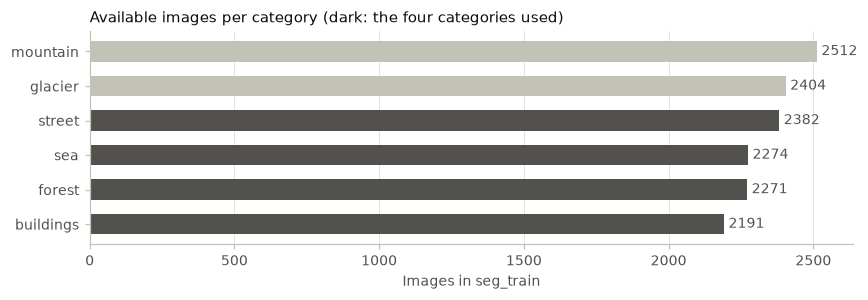

Unlabeled seg_pred images: 7,301


,buildings,forest,glacier,mountain,sea,street
seg_train,2191,2271,2404,2512,2274,2382
seg_test,437,474,553,525,510,501


,Training,Validation,Test
category,,,
sea,1500,100,100
forest,1500,100,100
street,1500,100,100
buildings,1500,100,100
total,6000,400,400


In [2]:
available = pd.DataFrame({
    split: {
        folder.name: sum(1 for _ in folder.glob("*.jpg"))
        for folder in sorted((DATA_DIR / split / split).iterdir()) if folder.is_dir()
    }
    for split in ["seg_train", "seg_test"]
})
unlabeled = sum(1 for _ in (DATA_DIR / "seg_pred" / "seg_pred").glob("*.jpg"))

manifests = {
    "Training": pd.read_csv(RECORD_DIR / "train_6000.csv"),
    "Validation": pd.read_csv(RECORD_DIR / "validation_400.csv"),
    "Test": pd.read_csv(TEST_RECORD_DIR / "test_400.csv"),
}
splits = pd.DataFrame({
    name: manifest["category"].value_counts() for name, manifest in manifests.items()
}).loc[CATEGORIES]
splits.loc["total"] = splits.sum()

fig, ax = plt.subplots(figsize=(8, 2.8))
order = available["seg_train"].sort_values().index
colors = [SECONDARY_INK if name in CATEGORIES else LIGHT_GRAY for name in order]
bars = ax.barh(order, available.loc[order, "seg_train"], color=colors, height=0.6)
ax.bar_label(bars, padding=3, color=SECONDARY_INK)
ax.grid(axis="x"); ax.grid(axis="y", visible=False)
ax.set_xlabel("Images in seg_train")
ax.set_title("Available images per category (dark: the four categories used)", loc="left")
plt.tight_layout()
plt.show()

print(f"Unlabeled seg_pred images: {unlabeled:,}")
display(available.T)
display(splits)

The six categories are balanced in the source data (2,191–2,512 training
images each), so drawing an equal number per category does not discard much
of any class.

We use three splits:

- **Training:** 1,500 images per category from `seg_train`.
- **Validation:** 100 images per category, from a disjoint part of
  `seg_train`.
- **Test:** 100 images per category from Kaggle's separate `seg_test`
  folder. They were reserved when the data were split and used only once,
  in the final evaluation.

### 1.3 Visual exploration

Six random training images per category.

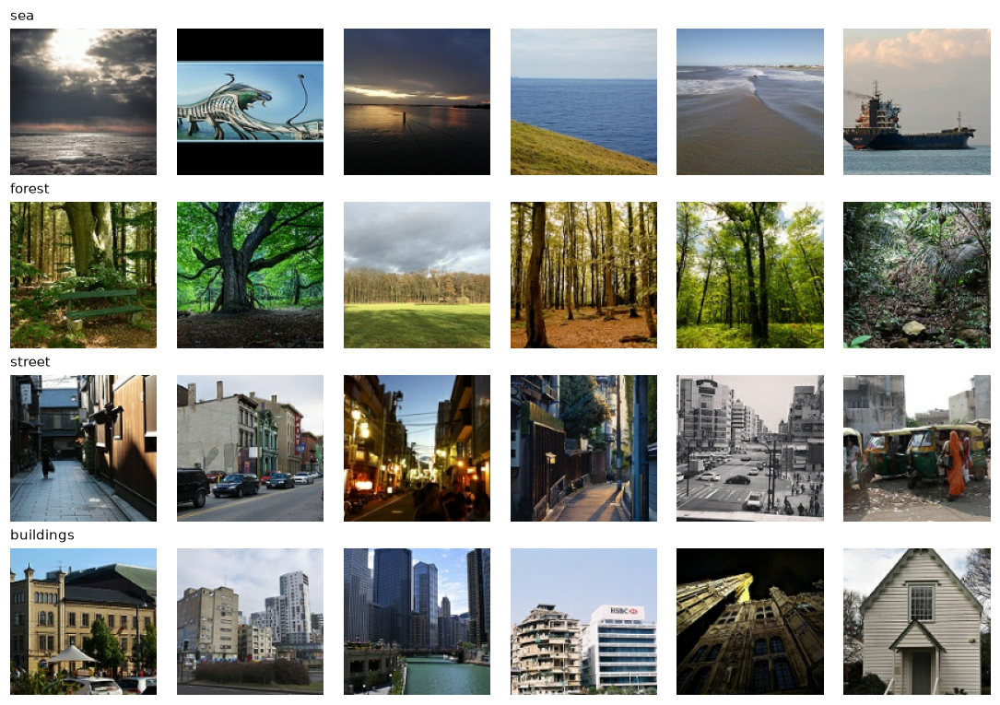

In [3]:
fig, axes = plt.subplots(4, 6, figsize=(10, 7))
for row, category in enumerate(CATEGORIES):
    train = manifests["Training"]
    paths = train.loc[train["category"] == category, "path"].sample(6, random_state=row)
    for col, (ax, path) in enumerate(zip(axes[row], paths)):
        ax.imshow(load_image(PROJECT_ROOT / path))
        ax.axis("off")
        if col == 0:
            ax.set_title(category, loc="left", fontsize=10)
plt.tight_layout()
plt.show()

To compare the categories numerically, we compute simple statistics on every
image of the three splits after preprocessing (Section 2), from the
luminance $Y = 0.299R + 0.587G + 0.114B$:

| Statistic | Definition |
| --- | --- |
| Brightness | Mean of $Y$ |
| Contrast | Standard deviation of $Y$ |
| Saturation | Mean HSV saturation |
| Fine detail | Root-mean-square of $Y$ minus a Gaussian blur of $Y$ (σ = 1 px): the energy of edges and texture at the scale of a few pixels |
| Red, green, blue | Mean of each channel |

The same pass records each file's size, colour mode, and checksum, which
Section 2 uses for the integrity checks.

6,800 images decoded and measured in 19 s


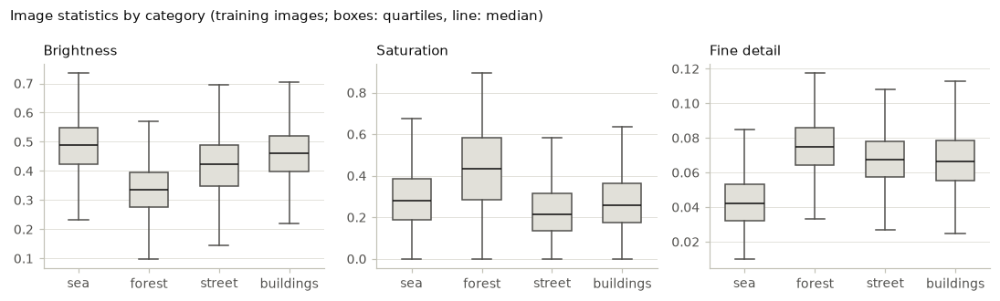

,brightness,contrast,saturation,fine detail,red,green,blue
category,,,,,,,
sea,0.483,0.204,0.297,0.044,0.453,0.494,0.508
forest,0.334,0.189,0.437,0.075,0.325,0.357,0.240
street,0.415,0.243,0.234,0.068,0.425,0.415,0.396
buildings,0.456,0.242,0.277,0.068,0.447,0.460,0.460


In [4]:
LUMA = np.array([0.299, 0.587, 0.114], np.float32)
FEATURES = ["brightness", "contrast", "saturation", "fine detail", "red", "green", "blue"]


def image_statistics(image):
    luma = image @ LUMA
    detail = luma - cv2.GaussianBlur(luma, (0, 0), 1.0, borderType=cv2.BORDER_REFLECT)
    return {
        "brightness": luma.mean(),
        "contrast": luma.std(),
        "saturation": cv2.cvtColor(image, cv2.COLOR_RGB2HSV)[..., 1].mean(),
        "fine detail": np.sqrt(np.mean(detail ** 2)),
        "red": image[..., 0].mean(),
        "green": image[..., 1].mean(),
        "blue": image[..., 2].mean(),
    }


rows, start = [], time.perf_counter()
for split, manifest in manifests.items():
    for path, category in manifest[["path", "category"]].itertuples(index=False):
        file = PROJECT_ROOT / path
        with Image.open(file) as source:
            width, height, mode = *source.size, source.mode
        image = load_image(file)
        rows.append({
            "split": split, "category": category, "path": path,
            "width": width, "height": height, "mode": mode,
            "md5": hashlib.md5(file.read_bytes()).hexdigest(),
            "non-finite values": int((~np.isfinite(image)).sum()),
            **image_statistics(image),
        })
image_stats = pd.DataFrame(rows)
log_memory("Dataset statistics computed")
print(f"{len(image_stats):,} images decoded and measured in {time.perf_counter() - start:.0f} s")

training_stats = image_stats[image_stats["split"] == "Training"]
fig, axes = plt.subplots(1, 3, figsize=(10, 3))
for ax, feature in zip(axes, ["brightness", "saturation", "fine detail"]):
    ax.boxplot(
        [training_stats.loc[training_stats["category"] == c, feature] for c in CATEGORIES],
        tick_labels=CATEGORIES, widths=0.55, patch_artist=True, showfliers=False,
        boxprops={"facecolor": "#e1e0d9", "edgecolor": SECONDARY_INK},
        medianprops={"color": INK}, whiskerprops={"color": SECONDARY_INK},
        capprops={"color": SECONDARY_INK},
    )
    ax.set_title(feature.capitalize(), loc="left")
fig.suptitle("Image statistics by category (training images; boxes: quartiles, line: median)",
             x=0.01, ha="left", fontsize=10)
plt.tight_layout()
plt.show()

display(training_stats.groupby("category")[FEATURES].mean().loc[CATEGORIES].round(3))

The four categories differ in ways that matter for filling a hole.

- **Sea:** the brightest category, with the least fine detail (median about
  0.04). Most of each image is smooth water and sky, which is easy to
  continue across a hole.
- **Forest:** the darkest and most saturated category, dominated by green,
  with the most fine detail (median about 0.075). Foliage is a dense,
  irregular texture.
- **Street and buildings:** they look alike statistically:
  - medium brightness;
  - low saturation;
  - the highest contrast (strong light and shadow);
  - fine detail between sea and forest, but arranged in straight edges,
    windows, and objects.

Forest, street, and buildings have about 60–80% more fine detail than sea
(medians).
Section 9.4 shows that this is the single property that best predicts how
hard a hole is to fill.

### 1.4 Correlation between image statistics

The dataset has no tabular features, so we look at the correlations between
the image statistics above, over the 6,000 training images (Pearson
coefficients).

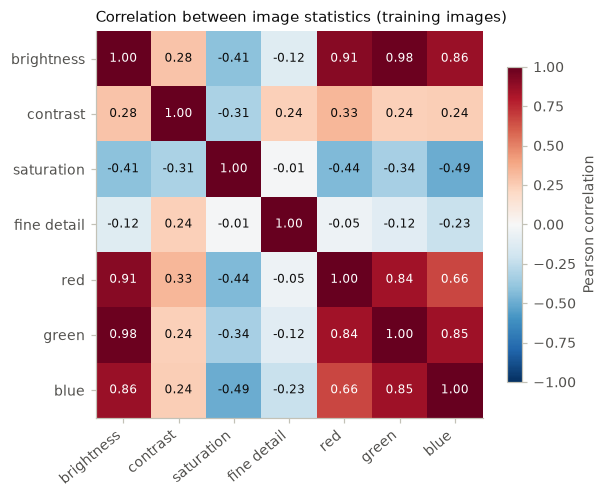

In [5]:
correlation = training_stats[FEATURES].corr()
fig, ax = plt.subplots(figsize=(5.6, 4.6))
im = ax.imshow(correlation, cmap="RdBu_r", vmin=-1, vmax=1)
ax.set_xticks(range(len(FEATURES)), FEATURES, rotation=40, ha="right")
ax.set_yticks(range(len(FEATURES)), FEATURES)
ax.grid(False)
for i in range(len(FEATURES)):
    for j in range(len(FEATURES)):
        value = correlation.iloc[i, j]
        ax.text(j, i, f"{value:.2f}", ha="center", va="center", fontsize=8,
                color="white" if abs(value) > 0.6 else INK)
fig.colorbar(im, ax=ax, shrink=0.8, label="Pearson correlation")
ax.set_title("Correlation between image statistics (training images)", loc="left")
plt.tight_layout()
plt.show()

- **Brightness and the colour channels:** strongly correlated (0.86–0.98),
  as expected, since brightness is a weighted sum of the channels. They
  carry little independent information.
- **Saturation:** negatively correlated with brightness (−0.41) and with
  blue (−0.49). Bright, bluish scenes (sky, sea) are pale, while the most
  saturated images are the darker green forests.
- **Fine detail:** almost uncorrelated with every colour statistic
  (|r| ≤ 0.24). How textured a scene is cannot be inferred from its colours.
  It is a separate property of the image, and the one that matters most for
  this task.

These are linear correlations across all four categories, so part of each
coefficient reflects the differences between categories shown above.

### 1.5 Masks: the regions to fill

The masks imitate what a user paints. A generator draws one of three shapes
at a random size and position:

- **brush strokes:** one to three thick lines;
- **a rounded block;**
- **a person silhouette.**

How each split gets its masks:

- **Training:** every batch draws new masks, so the model never sees the
  same image with the same hole twice. This works as unlimited data
  augmentation of the holes.
- **Validation and test:** each image has one fixed mask, saved in
  `records/`, so every method and every experiment is compared on exactly
  the same holes.

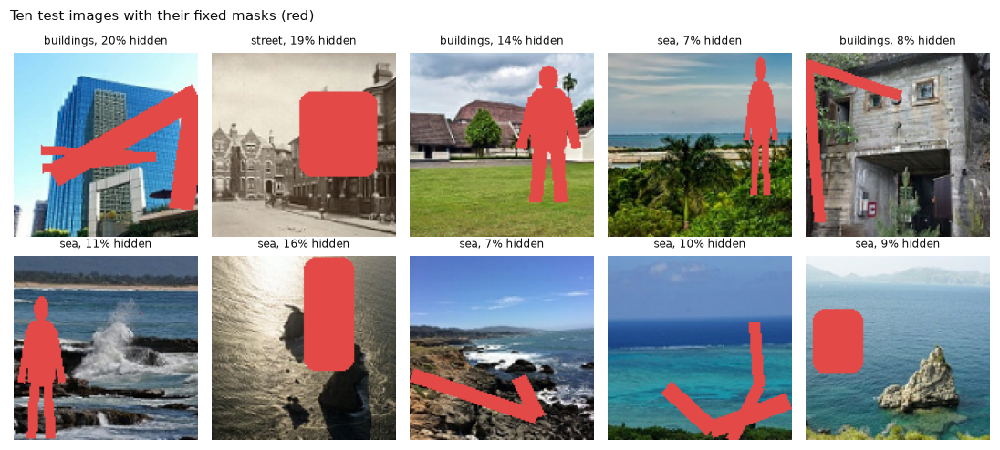

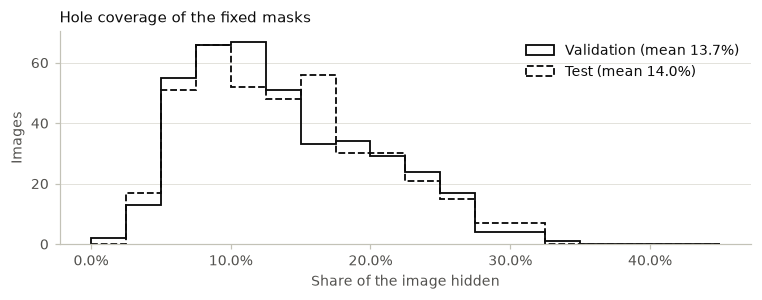

,mean,50%,min,max
Validation,13.7%,12.4%,1.6%,33.6%
Test,14.0%,13.0%,2.5%,32.3%


In [6]:
validation = load_validation_set(RECORD_DIR)
test_set = load_test_set(RECORD_DIR)
log_memory("Validation and test sets loaded")
categories = test_set.manifest["category"].to_numpy()
coverage = {"Validation": validation.masks.mean(axis=(1, 2, 3)),
            "Test": test_set.masks.mean(axis=(1, 2, 3))}

examples = np.random.default_rng(3).choice(len(test_set), 10, replace=False)
fig, axes = plt.subplots(2, 5, figsize=(10, 4.6))
for ax, index in zip(axes.flat, examples):
    overlay = test_set.originals[index].copy()
    overlay[test_set.masks[index, ..., 0] > 0.5] = [0.89, 0.29, 0.28]
    ax.imshow(overlay)
    ax.set_title(f"{categories[index]}, {coverage['Test'][index]:.0%} hidden", fontsize=8)
    ax.axis("off")
fig.suptitle("Ten test images with their fixed masks (red)", x=0.01, ha="left", fontsize=10)
plt.tight_layout()
plt.show()

fig, ax = plt.subplots(figsize=(7, 2.8))
bins = np.linspace(0, 0.45, 19)
for (name, values), style in zip(coverage.items(), ["-", "--"]):
    ax.hist(values, bins=bins, histtype="step", color=INK, linestyle=style, linewidth=1.2,
            label=f"{name} (mean {values.mean():.1%})")
ax.set_xlabel("Share of the image hidden")
ax.set_ylabel("Images")
ax.xaxis.set_major_formatter(mticker.PercentFormatter(1.0))
ax.legend(loc="upper right")
ax.set_title("Hole coverage of the fixed masks", loc="left")
plt.tight_layout()
plt.show()

display(pd.DataFrame(coverage).describe().loc[["mean", "50%", "min", "max"]].T.style.format("{:.1%}"))

On average the holes hide about 14% of the image, from thin strokes of 1–2%
to large silhouettes and blocks of more than a third of the image. Validation
and test have the same distribution, so validation results should carry over
to the test set (Section 9.6 confirms that they do).

## 2. Preprocessing

Every image goes through the same function, in training, validation, test,
and the app's first stage:

1. **Decode** the JPEG as three-channel RGB.
2. **Normalize:** convert from integers in [0, 255] to floating point in
   [0, 1]. The output layers are sigmoids, so predictions live in the same
   range.
3. **Resize** to 128 × 128 with bilinear interpolation. The original images
   are 150 × 150; 128 is a power of two, so three stride-2 downsamplings give
   exact 16 × 16 feature maps. It also keeps the training cost within a
   laptop GPU.
4. **Build the model input:** zero the hidden pixels and append the mask as
   a fourth channel, giving a 128 × 128 × 4 tensor. The target is the
   original image, and the loss is measured only inside the hole.

The function below is the one in the package, repeated here so the PDF shows
it. The check confirms that both give identical arrays.

In [7]:
IMAGE_SIZE = (128, 128)


def preprocess(path):
    """Decode a JPEG, scale to [0, 1], and resize to 128 × 128 (bilinear)."""
    image = tf.io.decode_jpeg(tf.io.read_file(str(path)), channels=3)
    image = tf.image.convert_image_dtype(image, tf.float32)   # uint8 [0, 255] -> float [0, 1]
    return tf.image.resize(image, IMAGE_SIZE).numpy()


def model_input(images, masks):
    """Masked image plus mask channel (N × 128 × 128 × 4); mask 1 = missing."""
    return np.concatenate([images * (1 - masks), masks], axis=-1)


sample_paths = [PROJECT_ROOT / path for path in manifests["Test"]["path"][:20]]
assert all(np.array_equal(preprocess(p), load_image(p)) for p in sample_paths)
assert np.array_equal(model_input(test_set.originals, test_set.masks), test_set.inputs)
print("preprocess() and model_input() match the package on the test images.")

preprocess() and model_input() match the package on the test images.


**Data-quality checks.** Images have no missing fields, but they can have
problems of their own:

- unreadable files;
- unexpected sizes or colour modes;
- invalid pixel values after conversion;
- nearly blank frames;
- duplicates, especially duplicates shared between splits, which would leak
  training images into the evaluation.

The table checks all 6,800 images used.

In [8]:
sizes = image_stats.groupby(["width", "height"]).size().sort_values(ascending=False)
near_blank = image_stats[image_stats["contrast"] < 0.03]
by_hash = image_stats.groupby("md5")
duplicate_groups = by_hash.filter(lambda group: len(group) > 1)
cross_split = by_hash["split"].nunique()
quality = pd.Series({
    "Images decoded": len(image_stats),
    "Not 150 × 150": int((sizes.drop((150, 150), errors="ignore")).sum()),
    "Not RGB in the file": int((image_stats["mode"] != "RGB").sum()),
    "Non-finite pixel values after preprocessing": int(image_stats["non-finite values"].sum()),
    "Nearly blank (luminance std < 0.03)": len(near_blank),
    "Files in exact-duplicate groups": len(duplicate_groups),
    "Exact duplicates shared between splits": int((cross_split > 1).sum()),
}, name="count").to_frame()
display(quality)
odd = image_stats[(image_stats["width"] != 150) | (image_stats["height"] != 150)]
print("Images that are not 150 × 150:")
display(odd.groupby(["split", "category"]).agg(
    images=("path", "size"), heights=("height", lambda h: sorted(set(h)))))
print("Exact-duplicate files:")
display(duplicate_groups.sort_values("md5")[["split", "category", "path"]]
        .assign(path=lambda d: d["path"].str.replace("data/intel-image-classification/", "", regex=False)))

,count
Images decoded,6800
Not 150 × 150,9
Not RGB in the file,0
Non-finite pixel values after preprocessing,0
Nearly blank (luminance std < 0.03),0
Files in exact-duplicate groups,4
Exact duplicates shared between splits,0


Images that are not 150 × 150:


images               heights
split    category                               
Test     forest          1                 [141]
Training buildings       1                 [124]
         forest          4  [108, 113, 133, 135]
         sea             2            [113, 140]
         street          1                 [113]

Exact-duplicate files:


,split,category,path
4108,Training,street,seg_train/seg_train/street/1495.jpg
4853,Training,buildings,seg_train/seg_train/buildings/4551.jpg
2210,Training,forest,seg_train/seg_train/forest/8689.jpg
2455,Training,forest,seg_train/seg_train/forest/8688.jpg


**What the checks found:**

- **Clean data:** all 6,800 files decode, are stored as RGB, have no invalid
  values after preprocessing, and none is blank.
- **Nine odd sizes:** nine images (0.13%) are 150 pixels wide but shorter
  than 150, from 108 to 141 pixels. They are complete photos, so they were
  kept. Resizing to 128 × 128 stretches them slightly in height, which does
  not affect a model that sees only local context.
- **Two duplicate pairs:** two pairs of identical files exist, both inside
  the training split. One photo appears both as `street` and as
  `buildings`. Two duplicates among 6,000 training images have no
  measurable effect, so they were left in place.
- **No leakage:** no file is shared between training, validation, and test.
  The test evaluation also searched for near-duplicates by comparing image
  layouts. It found one test photo of the same scene as a validation photo;
  Section 9.6 shows the results with and without it.

**No outlier filtering** beyond these checks is appropriate. Unusual
scenes, such as very dark streets or overexposed skies, are exactly the
cases a user may submit.

## 3. Methodology

We followed a staged plan. The initial plan was the standard set-up of
learned inpainting (Pathak et al., 2016):

- a convolutional encoder–decoder;
- trained from scratch with a reconstruction loss inside the hole;
- compared with a classical method on fixed validation images and masks.

Each later stage was adopted only when a measurement showed a specific
limitation of the previous one. Each change was guided by how the
inpainting literature handles that limitation. The survey by Quan et al.
(2024) gave the overall map of approaches.

| Phase | Question | What we did | Guided by | Outcome |
| --- | --- | --- | --- | --- |
| 1. Baseline | Can a small CNN beat classical inpainting? | Autoencoder, then U-Net with skip connections, trained with masked MAE; OpenCV Telea as the baseline | Pathak et al. (2016); Ronneberger et al. (2015); Telea (2004) | Close to OpenCV on thin strokes; fills blurry |
| 2. Diagnose the limits | Why are the fills blurry, and would a bigger model fix it? | Realistic masks; a wider receptive field; more data and capacity; overfitting, train–validation, and "oracle" diagnostics | Iizuka et al. (2017); Luo et al. (2016); Mathieu et al. (2016); Blau & Michaeli (2018) | The pixel loss, not model size, limits quality |
| 3. Coarse-to-fine refinement | How do we add realistic texture? | Second-stage refiner with gated convolutions, perceptual, style, and adversarial losses; then targeted fixes for its artifacts | Yu et al. (2018, 2019); Johnson et al. (2016); Gatys et al. (2016); Liu et al. (2018); Isola et al. (2017); Miyato et al. (2018) | Large perceptual gain; colour fringing removed; a faint grid remains |
| 4. Final evaluation and app | How good is it on unseen data, and how do we deliver it? | One evaluation on the reserved test set; app that chains our model with a pretrained diffusion model | Zhang et al. (2018); Bińkowski et al. (2018); Rombach et al. (2022); Meng et al. (2022) | Results in Section 9; app published |

**Rules we kept throughout:**

- **One change at a time, against a matched control.** Competing variants
  start from the same weights and see the same training batches and masks in
  the same order, so a difference comes from the change being tested.
- **A fixed validation protocol.** The validation images and masks were
  frozen once. Result tables are written once and must be reproduced by
  every later execution (`records/`).
- **Hypotheses and success criteria before training.** Each experiment
  states what result would support or reject its hypothesis before it runs.
- **Diagnose before scaling.** Before training a larger model, we first
  tested whether size was the limitation (Section 6.3).
- **Measure uncertainty.** We report paired, image-by-image differences
  with bootstrap 95% intervals. A second training seed showed how much two
  runs of the same model differ, about 0.004 in masked MAE. Smaller
  differences between single runs are not treated as findings.
- **The test set is used once,** after every model and setting was fixed.

**Measures.** Lower is better for all three:

- **Masked MAE (fidelity):** mean absolute error over the hidden pixels.
- **Perceptual distance (perceptual similarity):** a distance between deep
  VGG16 features of the result and the original (Simonyan & Zisserman,
  2015). It follows the unlearned form of LPIPS (Zhang et al., 2018).
- **KID × 1000 (realism):** Kernel Inception Distance (Bińkowski et al.,
  2018). It measures how far the distribution of results is from that of
  real images, using InceptionV3 features (Szegedy et al., 2016). Its
  estimator is unbiased, so values near zero, or slightly negative, mean
  "indistinguishable at this sample size".

## 4. Model Architecture

The model has two stages trained from scratch, plus a pretrained stage used
only in the app.

**Stage 1, coarse U-Net.**

- *Input:* the masked image and its mask.
- *Output:* a complete fill.
- *Parameters:* 3.3 M.

**Stage 2, low-chroma refiner.**

- *Input:* the U-Net's composed result and the mask.
- *Output:* a correction that adds texture.
- *Parameters:* 2.0 M.

**Training only (refiner):**

- a frozen VGG16 for the perceptual and style losses;
- a patch discriminator for the adversarial loss.

**App only:** Stable Diffusion 1.5 Inpainting, a pretrained model used
without retraining, completes stage 2's fill at 512 × 512.

In every stage, the pixels outside the hole are copied from the input.

### 4.1 Stage 1: the coarse U-Net

The architecture follows the U-Net of Ronneberger et al. (2015).

- **Encoder.** Three levels, each with two 3 × 3 convolutions and ReLU. A
  stride-2 convolution halves the resolution: 128 → 64 → 32 → 16.
- **Bottleneck.** At 16 × 16, two 3 × 3 convolutions and two dilated
  convolutions (rates 2 and 4) widen the receptive field. This lets
  predictions deep inside a large hole use background far from its edge
  (Iizuka et al., 2017; Yu et al., 2018).
- **Dropout.** A dropout of 0.2 regularizes the bottleneck.
- **Decoder.** It mirrors the encoder: nearest-neighbour upsampling,
  concatenation with the encoder features of the same resolution (skip
  connections), and two convolutions per level.
- **Output.** A 1 × 1 convolution with a sigmoid gives RGB in [0, 1].

**No batch normalization.** As in DeepFill (Yu et al., 2018), whose authors
removed it because it degraded colour coherence, the network has none. In
inpainting, batch statistics mix hidden and visible pixels, and their share
changes from image to image. We did not test a variant with batch
normalization.

**Loss.** The U-Net is trained with the masked mean absolute error,

$$\mathcal{L}_{\text{MAE}} = \frac{\sum_{i} m_i \, \lvert x_i - \hat{x}_i \rvert}{3 \sum_i m_i},$$

using Adam (Kingma & Ba, 2015).

The code below builds the architecture. Loading the saved weights into it
reproduces the trained model's predictions, which confirms that this code
is the trained architecture.

In [9]:
def masked_mae(y_true, y_pred):
    """Mean absolute error over hole pixels. y_true = original RGB + mask (4 channels)."""
    original, mask = y_true[..., :3], y_true[..., 3:]
    return tf.math.divide_no_nan(
        tf.reduce_sum(tf.abs(original - y_pred) * mask), 3.0 * tf.reduce_sum(mask)
    )


def conv_block(x, filters):
    x = layers.Conv2D(filters, 3, padding="same", activation="relu")(x)
    return layers.Conv2D(filters, 3, padding="same", activation="relu")(x)


def build_coarse_unet():
    inputs = keras.Input(shape=(128, 128, 4))          # masked RGB + mask
    x, skips = inputs, []
    for filters in [32, 64, 128]:                      # encoder: 128 -> 64 -> 32 -> 16
        x = conv_block(x, filters)
        skips.append(x)
        x = layers.Conv2D(filters, 3, strides=2, padding="same", activation="relu")(x)
    x = conv_block(x, 256)                             # bottleneck at 16 x 16
    for dilation in [2, 4]:
        x = layers.Conv2D(256, 3, padding="same", dilation_rate=dilation, activation="relu")(x)
    x = layers.Dropout(0.2)(x)
    for filters, skip in zip([128, 64, 32], reversed(skips)):   # decoder with skips
        x = layers.UpSampling2D()(x)
        x = layers.Concatenate()([x, skip])
        x = conv_block(x, filters)
    outputs = layers.Conv2D(3, 1, activation="sigmoid")(x)
    return keras.Model(inputs, outputs, name="coarse_unet")


def layer_table(model):
    return pd.DataFrame([
        {"layer": layer.name, "type": type(layer).__name__,
         "output shape": " × ".join(str(d) for d in layer.output.shape[1:]),
         "parameters": layer.count_params()}
        for layer in model.layers
    ]).set_index("layer")


saved_coarse = load_saved_model(COARSE_MODEL_FILE)
coarse_unet = build_coarse_unet()
coarse_unet.set_weights(saved_coarse.get_weights())
check_inputs = test_set.inputs[:32]
difference = np.abs(coarse_unet.predict(check_inputs, verbose=0)
                    - saved_coarse.predict(check_inputs, verbose=0)).max()
print(f"Parameters: {coarse_unet.count_params():,}; largest difference from the saved "
      f"model's predictions: {difference:.1e}")
assert difference < 1e-5
with pd.option_context("display.max_rows", 40):
    display(layer_table(coarse_unet))

Parameters: 3,321,155; largest difference from the saved model's predictions: 0.0e+00


,type,output shape,parameters
layer,,,
input_layer,InputLayer,128 × 128 × 4,0
conv2d,Conv2D,128 × 128 × 32,1184
conv2d_1,Conv2D,128 × 128 × 32,9248
conv2d_2,Conv2D,64 × 64 × 32,9248
conv2d_3,Conv2D,64 × 64 × 64,18496
conv2d_4,Conv2D,64 × 64 × 64,36928
conv2d_5,Conv2D,32 × 32 × 64,36928
conv2d_6,Conv2D,32 × 32 × 128,73856
conv2d_7,Conv2D,32 × 32 × 128,147584


### 4.2 Stage 2: the low-chroma refiner

The refiner's job is to add texture to the U-Net's smooth fill. Its design
combines four ideas from the literature with one constraint of our own.

1. **Gated convolutions** (Yu et al., 2019). Each layer computes features
   $\phi(W_f * z)$ (ELU activation) and a gate $\sigma(W_g * z)$ from the
   same input $z$, and multiplies them. The gate is a learned, soft,
   per-pixel mask. It lets the network treat features computed from filled
   pixels differently from those computed from real ones. That distinction
   matters here because half of the input is the U-Net's guess.
2. **Encoder–decoder with dilations.** Two stride-2 gated layers go down to
   32 × 32. Three dilated gated layers (rates 2, 4, 8) follow, then a
   decoder with skip connections.
3. **A residual in logit space.** The network outputs a correction $r$, and
   the refined pixel is $\sigma(\operatorname{logit}(c) + r)$, where $c$
   is the U-Net's value. The last layer starts at zero, so an untrained
   refiner reproduces the U-Net exactly. Training can only move away from a
   good fill; it never starts from noise.
4. **Our low-chroma constraint.** The correction's three channels are read
   as luminance and two colour (chroma) channels in YCbCr space. The chroma
   channels are blurred with a Gaussian (σ = 2 px) before conversion to RGB.
   Fine detail can therefore be added almost only in brightness. Natural
   photos have the same property: in our images, colour carries about 1% of
   the fine-detail energy. Image codecs exploit it by storing colour at
   lower resolution. This constraint removed the colour fringing of the
   first refiner (Section 5).

In [10]:
CHROMA_SIGMA = 2.0
YCBCR_TO_RGB = np.array([[1.0, 1.0, 1.0],          # rows map the Y, Cb, Cr residuals to RGB
                         [0.0, -0.344136, 1.772],
                         [1.402, -0.714136, 0.0]], np.float32)


def gated_conv(x, filters, kernel_size=3, strides=1, dilation_rate=1, name=None):
    """Features times a learned sigmoid gate (Yu et al., 2019)."""
    features = layers.Conv2D(filters, kernel_size, strides=strides, dilation_rate=dilation_rate,
                             padding="same", name=f"{name}_features")(x)
    features = layers.ELU(name=f"{name}_elu")(features)
    gate = layers.Conv2D(filters, kernel_size, strides=strides, dilation_rate=dilation_rate,
                         padding="same", activation="sigmoid", name=f"{name}_gate")(x)
    return layers.Multiply(name=name)([features, gate])


def build_refiner():
    inputs = keras.Input(shape=(128, 128, 4))           # coarse composite + mask
    x128 = gated_conv(inputs, 32, kernel_size=5, name="enc128")
    x = gated_conv(x128, 64, strides=2, name="down64")
    x64 = gated_conv(x, 64, name="enc64")
    x = gated_conv(x64, 128, strides=2, name="down32")
    x = gated_conv(x, 128, name="enc32")
    for rate in [2, 4, 8]:
        x = gated_conv(x, 128, dilation_rate=rate, name=f"dilated{rate}")
    x = gated_conv(x, 128, name="dec32")
    x = layers.UpSampling2D(name="up64")(x)
    x = layers.Concatenate(name="skip64")([x, x64])
    x = gated_conv(x, 64, name="dec64")
    x = layers.UpSampling2D(name="up128")(x)
    x = layers.Concatenate(name="skip128")([x, x128])
    x = gated_conv(x, 32, name="dec128")
    residual = layers.Conv2D(3, 3, padding="same", kernel_initializer="zeros",
                             bias_initializer="zeros", name="residual")(x)
    return keras.Model(inputs, residual, name="low_chroma_refiner")


def chroma_kernel(sigma=CHROMA_SIGMA):
    radius = int(3 * sigma)
    taps = np.exp(-np.arange(-radius, radius + 1, dtype=np.float32) ** 2 / (2 * sigma ** 2))
    taps /= taps.sum()
    return np.tile(np.outer(taps, taps)[:, :, None, None], (1, 1, 2, 1))


def low_chroma_residual(raw):
    """Read the residual as (Y, Cb, Cr), blur Cb and Cr, convert to RGB."""
    chroma = tf.nn.depthwise_conv2d(raw[..., 1:], chroma_kernel(), [1, 1, 1, 1], "SAME")
    return tf.tensordot(tf.concat([raw[..., :1], chroma], axis=-1), YCBCR_TO_RGB, axes=1)


def refine_low_chroma(refiner, coarse, masks, training=False):
    """refined = sigmoid(logit(coarse) + low-chroma residual) inside the hole."""
    raw = refiner(tf.concat([coarse, masks], axis=-1), training=training)
    clipped = tf.clip_by_value(coarse, 1e-3, 1 - 1e-3)
    logits = tf.math.log(clipped) - tf.math.log1p(-clipped)
    refined = tf.sigmoid(logits + low_chroma_residual(raw))
    return coarse * (1 - masks) + refined * masks      # original pixels kept outside the hole


refiner_file, package_refine = SAVED_REFINERS["Low-chroma refiner"]
saved_refiner = load_saved_model(refiner_file)
refiner = build_refiner()
refiner.set_weights(saved_refiner.get_weights())

check_masks = test_set.masks[:32]
check_coarse = test_set.visible[:32] + coarse_unet.predict(check_inputs, verbose=0) * check_masks
ours = refine_low_chroma(refiner, tf.constant(check_coarse), tf.constant(check_masks)).numpy()
package = refine_images(saved_refiner, check_coarse, check_masks, package_refine)
print(f"Parameters: {refiner.count_params():,}; largest difference from the saved refiner: "
      f"{np.abs(ours - package).max():.1e}")
assert np.abs(ours - package).max() < 1e-5

blocks = [layer for layer in refiner.layers
          if isinstance(layer, (layers.Multiply, layers.UpSampling2D, layers.Concatenate))
          or layer.name == "residual"]
display(pd.DataFrame([
    {"block": layer.name,
     "type": "gated conv" if isinstance(layer, layers.Multiply) else type(layer).__name__,
     "output shape": " × ".join(str(d) for d in layer.output.shape[1:]),
     "parameters": (sum(refiner.get_layer(f"{layer.name}_{part}").count_params()
                        for part in ["features", "gate"])
                    if isinstance(layer, layers.Multiply) else layer.count_params())}
    for layer in blocks
]).set_index("block"))

Parameters: 2,018,403; largest difference from the saved refiner: 0.0e+00


,type,output shape,parameters
block,,,
enc128,gated conv,128 × 128 × 32,6464
down64,gated conv,64 × 64 × 64,36992
enc64,gated conv,64 × 64 × 64,73856
down32,gated conv,32 × 32 × 128,147712
enc32,gated conv,32 × 32 × 128,295168
dilated2,gated conv,32 × 32 × 128,295168
dilated4,gated conv,32 × 32 × 128,295168
dilated8,gated conv,32 × 32 × 128,295168
dec32,gated conv,32 × 32 × 128,295168


### 4.3 How the refiner is trained

The U-Net is frozen while the refiner trains. For a training image $x$ with
mask $m$, the refiner's result $\hat{x}$ is compared with the truth by four
terms.

1. **Masked L1**, as for the U-Net: it keeps colours and layout right.
2. **Perceptual loss** (Johnson et al., 2016): the L1 distance between
   frozen VGG16 activations (`block1_pool` to `block3_pool`) of $\hat{x}$
   and $x$, weighted by the mask resized to each layer. It compares *what
   the image looks like* rather than exact pixels.
3. **Style loss** (Gatys et al., 2016; Liu et al., 2018): the L1 distance
   between Gram matrices $G = F^\top F / N$ of the same activations,
   computed over the hole. A Gram matrix records which features occur
   together, regardless of where. It rewards texture of the right
   *character* even when that texture is not pixel-aligned with the truth.
4. **Adversarial loss**, from an SN-PatchGAN discriminator (Isola et al.,
   2017; Yu et al., 2019):
   - **Architecture:** four stride-2 convolutions with spectral
     normalization (Miyato et al., 2018). The normalization bounds each
     layer's Lipschitz constant and stabilizes training.
   - **Output:** an 8 × 8 grid of real/fake scores, one per image patch.
   - **What is scored:** only patches that overlap the hole. The
     discriminator uses the hinge loss; the refiner tries to raise the
     scores of its patches.

**How the terms are weighted.** Published loss weights depend on how each
implementation normalizes its terms, so they do not transfer.

- **Perceptual and style weights:** we calibrated them so that, at the
  start of training, each weighted term has the same gradient norm with
  respect to the output image as the L1 term.
- **Adversarial weight:** it is recomputed at every step so that its
  gradient is half the size of the reconstruction gradient,

$$\lambda_{\text{adv}} = 0.5 \cdot \frac{\lVert \nabla_{\hat{x}}\, \mathcal{L}_{\text{rec}} \rVert}{\lVert \nabla_{\hat{x}}\, \mathcal{L}_{\text{adv}} \rVert}.$$

This adaptive rule follows Esser et al. (2021). We adopted it after a fixed
adversarial weight let the adversarial gradient grow from 0.2 to 4.1 times
the reconstruction gradient within 50 updates, which caused strong colour
shifts.

**Each training step:**

1. update the discriminator once on real images and current results;
2. combine the reconstruction and adversarial gradients with respect to the
   output image;
3. backpropagate them through the refiner in one pass, using Adam with
   learning rate $10^{-4}$, batches of 16, and 3,000 updates (8 epochs).

The training step itself is `photo_retouch.training.make_train_step`. The
losses and the discriminator are below, followed by the calibrated weights
and the size of each term on 16 test images.

In [11]:
def hole_l1(images, results, masks):
    return tf.math.divide_no_nan(tf.reduce_sum(tf.abs(images - results) * masks),
                                 3.0 * tf.reduce_sum(masks))


def perceptual_and_style(truth_features, result_features, masks):
    """Hole-weighted VGG16 feature L1 (perceptual) and Gram-matrix L1 (style)."""
    perceptual, style = 0.0, 0.0
    for truth, result in zip(truth_features, result_features):
        weights = tf.image.resize(masks, tf.shape(truth)[1:3], method="area")
        channels = tf.cast(tf.shape(truth)[-1], tf.float32)
        perceptual += tf.math.divide_no_nan(tf.reduce_sum(tf.abs(truth - result) * weights),
                                            tf.reduce_sum(weights) * channels)
        normalizer = tf.reduce_sum(weights, axis=[1, 2, 3])[:, None, None] * channels + 1e-6
        truth_gram = tf.einsum("bhwc,bhwd->bcd", truth * weights, truth) / normalizer
        result_gram = tf.einsum("bhwc,bhwd->bcd", result * weights, result) / normalizer
        style += tf.reduce_mean(tf.abs(truth_gram - result_gram))
    return perceptual / len(truth_features), style / len(truth_features)


def build_patch_discriminator():
    """SN-PatchGAN: four stride-2 spectrally normalized convolutions, 8 × 8 score grid."""
    inputs = keras.Input(shape=(128, 128, 4))           # image + mask
    x = inputs
    for filters in [64, 128, 256, 256]:
        x = layers.SpectralNormalization(layers.Conv2D(filters, 5, strides=2, padding="same"))(x)
        x = layers.LeakyReLU(negative_slope=0.2)(x)
    scores = layers.SpectralNormalization(layers.Conv2D(1, 3, padding="same"))(x)
    return keras.Model(inputs, scores, name="sn_patch_discriminator")


def hinge_discriminator_loss(real_scores, fake_scores, weights):
    def patch_mean(values):
        return tf.math.divide_no_nan(tf.reduce_sum(values * weights), tf.reduce_sum(weights))
    return patch_mean(tf.nn.relu(1.0 - real_scores)) + patch_mean(tf.nn.relu(1.0 + fake_scores))


discriminator = build_patch_discriminator()
assert discriminator.count_params() == package_discriminator().count_params()
perceptual_weight, style_weight, adversarial_ratio = saved_loss_weights()

loss_features = vgg16_features(LOSS_LAYERS)
images16, masks16 = tf.constant(test_set.originals[:16]), tf.constant(test_set.masks[:16])
truth_features = loss_features(vgg_preprocess(images16), training=False)
coarse16 = tf.constant(check_coarse[:16])
rows = []
for name, result in [("Coarse U-Net (refiner's starting point)", coarse16),
                     ("Low-chroma refiner", refine_low_chroma(refiner, coarse16, masks16))]:
    perceptual, style = perceptual_and_style(
        truth_features, loss_features(vgg_preprocess(result), training=False), masks16)
    rows.append({"result": name,
                 "L1": float(hole_l1(images16, result, masks16)),
                 "perceptual × weight": float(perceptual) * perceptual_weight,
                 "style × weight": float(style) * style_weight})
print(f"Discriminator parameters: {discriminator.count_params():,} (training only)")
print(f"Calibrated weights: perceptual {perceptual_weight:.2e}, style {style_weight:.2e}, "
      f"adversarial gradient ratio {adversarial_ratio}")
display(pd.DataFrame(rows).set_index("result").round(4))

Discriminator parameters: 2,672,514 (training only)
Calibrated weights: perceptual 2.14e-04, style 8.88e-05, adversarial gradient ratio 0.5


,L1,perceptual × weight,style × weight
result,,,
Coarse U-Net (refiner's starting point),0.0756,0.0444,0.0382
Low-chroma refiner,0.0828,0.0428,0.0211


**At the refiner's starting point** (the U-Net's fill), the three weighted
terms are of comparable size (0.076, 0.044, and 0.038). The calibration
balanced their gradients, so no term dominates training.

**After training**, on these 16 test images, the refiner has:

- cut the weighted style term by 45%;
- cut the perceptual term by 4%;
- raised the L1 term by 10%.

It accepts a little pixel error in exchange for texture statistics much
closer to the truth's. Section 6.2 shows the same pattern over the whole
training run.

### 4.4 Stage 3, only in the app: a pretrained diffusion model

At 128 × 128, our model gets colours and layout right but cannot produce
photographic detail. A real photo is also much larger than 128 pixels. The
app therefore adds a pretrained model, Stable Diffusion 1.5 Inpainting
(Rombach et al., 2022). It is used as published, without fine-tuning. The
app's steps:

1. **Crop.** Take a square crop around the painted region, about twice its
   size, and resize it to 128 × 128.
2. **Stage 1.** Our two stages fill the hole in the crop.
3. **Enlarge.** Enlarge our fill to 512 × 512.
4. **Partial noising.** Replace 70% of the fill with noise (the
   "refinement strength" 0.7). The diffusion model then denoises it over
   21 of its 30 steps. Starting from a partially noised image keeps the
   large-scale structure of our fill while the model adds detail. This is
   the mechanism of SDEdit (Meng et al., 2022).
5. **Paste.** Paste the result back into the full-resolution photo, with a
   blend margin of a few pixels.

The roles divide naturally:

- **Our model:** decides *what* goes in the hole: colours, horizon, layout.
- **The pretrained model:** decides *how it looks* at high resolution.

Section 9 measures what each contributes.

**Pretrained networks in the project, none fine-tuned:**

- **VGG16 (frozen):** used for the training losses and the perceptual
  distance.
- **InceptionV3:** used for KID.
- **Stable Diffusion 1.5 Inpainting:** the third stage of the app.

### 4.5 The two trained stages as one Keras model

For prediction and evaluation, the two stages are wrapped in a single
`keras.Model` subclass. `predict` and `evaluate` then work on the complete
model.

In [12]:
class TwoStageInpainter(keras.Model):
    """Coarse U-Net followed by the low-chroma refiner.

    Input: masked image + mask (N × 128 × 128 × 4). Output: the composed
    result, with the original pixels outside the hole.
    """

    def __init__(self, coarse, refiner, **kwargs):
        super().__init__(**kwargs)
        self.coarse = coarse
        self.refiner = refiner

    def call(self, inputs, training=False):
        visible, masks = inputs[..., :3], inputs[..., 3:]
        coarse = visible + self.coarse(inputs, training=training) * masks
        return refine_low_chroma(self.refiner, coarse, masks, training=training)


two_stage = TwoStageInpainter(coarse_unet, refiner, name="photo_retouch")
log_memory("Models built")
print(f"Trainable parameters used at inference: "
      f"{coarse_unet.count_params() + refiner.count_params():,}")

Trainable parameters used at inference: 5,339,558


## 5. Hyperparameter Tuning

We did not run a blind grid or random search. Each training run takes from
about 20 minutes to a few hours on the laptop GPU, so a broad search was
not affordable. Instead, each hyperparameter was changed when a diagnostic
pointed at it. Every change was tested with a fixed training budget against
a matched control, on the frozen validation set. The table summarizes the
decisions. The intermediate models and their full results are in
`01_training.ipynb` and `02_refinement.ipynb`.

| Hyperparameter | Values tested | Chosen | Evidence (validation set) |
| --- | --- | --- | --- |
| Learning rate (U-Net) | 1e-3; then 1e-4 for fine-tuning | 1e-3, then 1e-4 | Fine-tuning at 1e-4 lowered the validation loss by 4.0% (0.0998 → 0.0958) |
| Early stopping | patience 3–4 epochs on the validation loss, best weights restored | 4 (training), 3 (fine-tuning) | Stops when the validation loss stalls; keeps the best checkpoint |
| Batch size | 16 | 16 | Fits comfortably in 16 GB of shared memory |
| Training masks | strokes only; strokes + blocks + silhouettes | mixed | Object-shaped holes were the weak case; validation loss on mixed masks fell 1.2% (0.1270 → 0.1255) after adapting |
| Receptive field | no dilation; dilated bottleneck (2, 4, 8) | dilated | Validation loss −16.9% (0.1255 → 0.1043); predictions at the hole's centre began to depend on the scene |
| Capacity and data | 0.67 M parameters on 2,000 images; 3.3 M on 6,000 | 3.3 M, 6,000 | Validation loss −4.3% (0.1043 → 0.0998): a small gain for 5 × the parameters and 3 × the data (Section 6.3) |
| Inference strategy | one pass; progressive filling (7 passes) | one pass | No gain on average; error propagated in rings |
| Adversarial weight | fixed (0.2 of the L1 gradient at the start); fixed 0.03; adaptive, ratio 0.5 | adaptive 0.5 | The fixed weight drifted from 0.2 to 4.1 × the L1 gradient in 50 updates and shifted colours |
| Perceptual and style weights | calibrated so that each term's gradient matches the L1 gradient at the start | calibrated | Published weights (e.g. Liu et al., 2018) depend on how each term is normalized and do not transfer |
| Style weight | × 0, × 1, × 10, × 100 the calibrated value | × 1 | See the figure below |
| Chroma constraint | none; Gaussian blur of the chroma residual, σ = 2 | σ = 2 | Excess colour detail fell from 3.84 to 1.09 × the truth; perceptual distance unchanged (+0.003, 95% CI [−0.003, +0.008]) |
| Decoder upsampling | nearest neighbour; bilinear | nearest | Bilinear's small gain with one seed reversed with a second seed |
| Diffusion strength (app) | 0 to 1 | 0.7 | Chosen by eye on unlabeled `seg_pred` photos, not on validation or test images |

Two of these decisions are shown below:

- **Capacity:** the validation loss of the successive U-Nets against their
  size.
- **Style weight:** the sweep for the refiner.

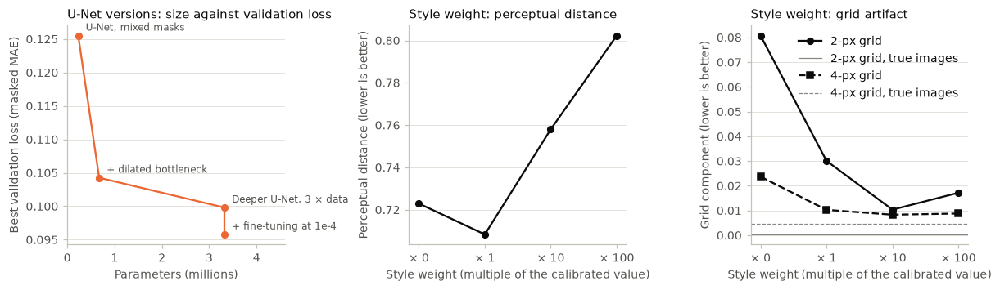

,training images,parameters,best validation loss
model,,,
"U-Net, mixed masks",2000,231971,0.1255
+ dilated bottleneck,2000,674723,0.1043
"Deeper U-Net, 3 × data",6000,3321155,0.0998
+ fine-tuning at 1e-4,6000,3321155,0.0958


In [13]:
histories = json.loads((RECORD_DIR / "training_histories.json").read_text())
unet_versions = pd.DataFrame([
    {"model": "U-Net, mixed masks", "file": "best_unet_mixed.keras", "history": "history_mixed",
     "training images": 2000},
    {"model": "+ dilated bottleneck", "file": "best_context_unet.keras", "history": "history_context",
     "training images": 2000},
    {"model": "Deeper U-Net, 3 × data", "file": "best_deep_unet_6000.keras", "history": "history_deep",
     "training images": 6000},
    {"model": "+ fine-tuning at 1e-4", "file": COARSE_MODEL_FILE, "history": "history_deep_tuned",
     "training images": 6000},
])
unet_versions["parameters"] = [load_saved_model(f).count_params() for f in unet_versions["file"]]
unet_versions["best validation loss"] = [
    min(histories[h]["metrics"]["val_loss"]) for h in unet_versions["history"]]

style = pd.read_csv(RECORD_DIR / "refinement_style_weight" / "style_weight_summary.csv")
style_grid = pd.read_csv(RECORD_DIR / "refinement_style_weight" / "grid_periodicity.csv")
true_grid = style_grid[style_grid["method"] == "True image"].set_index("direction")

fig, axes = plt.subplots(1, 3, figsize=(11, 3.3))
ax = axes[0]
ax.plot(unet_versions["parameters"] / 1e6, unet_versions["best validation loss"], "-o",
        color=METHOD_COLORS["Coarse U-Net"], markersize=5)
for _, row in unet_versions.iterrows():
    ax.annotate(row["model"], (row["parameters"] / 1e6, row["best validation loss"]),
                textcoords="offset points", xytext=(6, 4), fontsize=8, color=SECONDARY_INK)
ax.set_xlabel("Parameters (millions)")
ax.set_ylabel("Best validation loss (masked MAE)")
ax.set_xlim(0, 4.6)
ax.set_title("U-Net versions: size against validation loss", loc="left")

weights = style["style multiple"].astype(str).str.replace("^", "× ", regex=True)
ax = axes[1]
ax.plot(weights, style["feature_distance"], "-o", color=INK, markersize=5)
ax.set_xlabel("Style weight (multiple of the calibrated value)")
ax.set_ylabel("Perceptual distance (lower is better)")
ax.set_title("Style weight: perceptual distance", loc="left")

ax = axes[2]
for period, marker, linestyle in [(2, "o", "-"), (4, "s", "--")]:
    mean = style[[f"grid {period} px (h)", f"grid {period} px (v)"]].mean(axis=1)
    ax.plot(weights, mean, marker=marker, linestyle=linestyle, color=INK, markersize=5,
            label=f"{period}-px grid")
    ax.axhline(true_grid[f"period {period} px"].mean(), color=MUTED_INK, linestyle=linestyle,
               linewidth=0.8, label=f"{period}-px grid, true images")
ax.set_xlabel("Style weight (multiple of the calibrated value)")
ax.set_ylabel("Grid component (lower is better)")
ax.legend()
ax.set_title("Style weight: grid artifact", loc="left")
plt.tight_layout()
plt.show()
display(unet_versions.drop(columns=["file", "history"]).set_index("model").round(4))

**Reading the figure.**

- **Left: size against validation loss.** Widening the receptive field
  brought the largest improvement, with only a small increase in size.
  Multiplying the parameters by five and the data by three brought a much
  smaller one. Section 6.3 explains why.
- **Middle and right: style weight.**
  - Without the style term (× 0), the refiner develops a strong grid of
    2-pixel blocks. This agrees with Liu et al. (2018), who needed a style
    term to suppress such artifacts.
  - Raising the weight above the calibrated value (× 10, × 100) worsens the
    perceptual distance steadily.
  - It does not remove the grid consistently: the 4-pixel component stays
    above the level of real images.
  - The calibrated weight (× 1) has the best perceptual distance and was
    kept.

## 6. Training and Validation History

### 6.1 The coarse U-Net

The final U-Net was trained in two phases:

1. 20 epochs at learning rate $10^{-3}$;
2. 10 epochs of fine-tuning at $10^{-4}$.

Both phases used 6,000 training images with new random masks in every batch,
and validation on the 400 fixed validation images and masks. Keras recorded
the loss of each epoch (`model.history`).

**Accuracy is not defined for this task:** the output is an image, not a
class. The masked MAE plays both roles here, as the loss and as the metric.

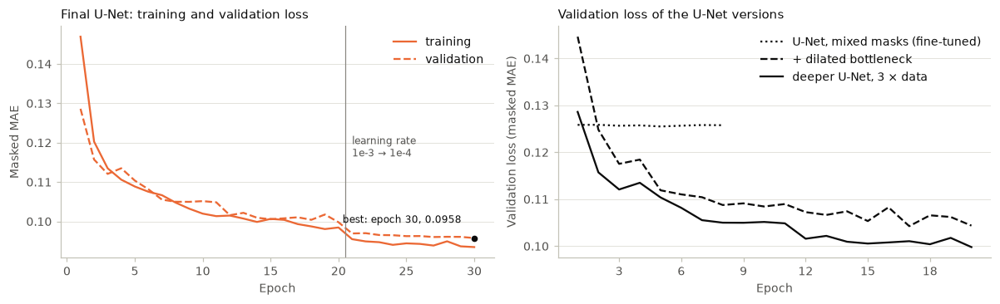

Validation minus training loss, last 10 epochs: mean +0.0020


In [14]:
deep, tuned = histories["history_deep"]["metrics"], histories["history_deep_tuned"]["metrics"]
train_loss = deep["loss"] + tuned["loss"]
val_loss = deep["val_loss"] + tuned["val_loss"]
epochs = np.arange(1, len(train_loss) + 1)
best = int(np.argmin(val_loss))

fig, axes = plt.subplots(1, 2, figsize=(11, 3.4))
ax = axes[0]
color = METHOD_COLORS["Coarse U-Net"]
ax.plot(epochs, train_loss, "-", color=color, label="training")
ax.plot(epochs, val_loss, "--", color=color, label="validation")
ax.axvline(len(deep["loss"]) + 0.5, color=MUTED_INK, linewidth=0.8)
ax.text(len(deep["loss"]) + 1, 0.122, "learning rate\n1e-3 → 1e-4", color=SECONDARY_INK,
        fontsize=8, va="top")
ax.plot(epochs[best], val_loss[best], "o", color=INK, markersize=4)
ax.annotate(f"best: epoch {epochs[best]}, {val_loss[best]:.4f}", (epochs[best], val_loss[best]),
            textcoords="offset points", xytext=(-10, 12), ha="right", fontsize=8)
ax.set_xlabel("Epoch")
ax.set_ylabel("Masked MAE")
ax.legend(loc="upper right")
ax.set_title("Final U-Net: training and validation loss", loc="left")

ax = axes[1]
for key, label, style in [("history_mixed", "U-Net, mixed masks (fine-tuned)", ":"),
                          ("history_context", "+ dilated bottleneck", "--"),
                          ("history_deep", "deeper U-Net, 3 × data", "-")]:
    values = histories[key]["metrics"]["val_loss"]
    ax.plot(np.arange(1, len(values) + 1), values, linestyle=style, color=INK, label=label)
ax.xaxis.set_major_locator(mticker.MaxNLocator(integer=True))
ax.set_xlabel("Epoch")
ax.set_ylabel("Validation loss (masked MAE)")
ax.legend(loc="upper right")
ax.set_title("Validation loss of the U-Net versions", loc="left")
plt.tight_layout()
plt.show()

gap = np.array(val_loss) - np.array(train_loss)
print(f"Validation minus training loss, last 10 epochs: mean {gap[-10:].mean():+.4f}")

**Left: the final U-Net.**

- **Fast start.** Both losses fall quickly for about eight epochs, then
  flatten.
- **No overfitting.** The validation loss follows the training loss
  closely: over the last ten epochs it exceeds it by only 0.002 on average.
  Dropout and the fresh random masks in every batch act as regularizers.
- **The learning-rate switch.** At epoch 21, the change to $10^{-4}$ lowers
  both losses at once, and the best validation loss falls from 0.0998 to
  0.0958. The larger steps had been oscillating around a minimum; smaller
  steps settle into it.
- **Stopping point.** The best epoch is the last one, but over the final
  five epochs the validation loss improved by less than 0.0001 per epoch.
  More epochs would add little.

**Right: the three U-Net versions.**

- The first U-Net, fine-tuned on mixed masks, stayed at 0.126 from its first
  epoch: it could not improve on object-shaped holes.
- The dilated bottleneck brought it to 0.104.
- The deeper network trained on three times the data brought it to 0.100.

Section 6.3 explains why the last step gained so little.

### 6.2 The refiner

The refiner was trained with a custom loop rather than `model.fit`: each
step updates a discriminator and the refiner, with the adaptive weight
(Section 4.3). Every update was logged. The curves are 100-update moving
averages. The perceptual and style values are the unweighted distances.

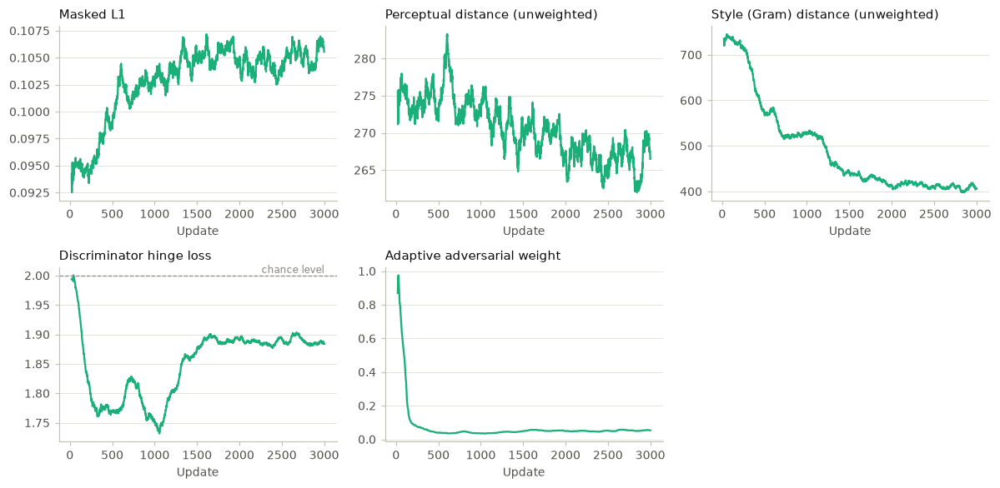

,first 100 updates,last 250 updates
l1,0.0948,0.1052
perceptual,275.1681,265.7694
style,735.2000,406.5584
adv_weight,0.4811,0.0521
discriminator_loss,1.9544,1.8843


In [15]:
log = pd.read_csv(RECORD_DIR / "refinement_followup" / "training_log.csv").set_index("step")
log = log[[c for c in log.columns if c.startswith("low_chroma_")]]
log.columns = [c.removeprefix("low_chroma_") for c in log.columns]
smooth = log.rolling(100, min_periods=20).mean()

panels = [("l1", "Masked L1"), ("perceptual", "Perceptual distance (unweighted)"),
          ("style", "Style (Gram) distance (unweighted)"),
          ("discriminator_loss", "Discriminator hinge loss"),
          ("adv_weight", "Adaptive adversarial weight")]
fig, axes = plt.subplots(2, 3, figsize=(11, 5.4))
for ax, (column, title) in zip(axes.flat, panels):
    ax.plot(smooth.index, smooth[column], color=METHOD_COLORS["Low-chroma refiner"])
    ax.set_title(title, loc="left")
    ax.set_xlabel("Update")
axes.flat[3].axhline(2.0, color=MUTED_INK, linewidth=0.8, linestyle="--")
axes.flat[3].text(3000, 2.0, "chance level", color=MUTED_INK, fontsize=8, ha="right", va="bottom")
axes.flat[5].axis("off")
plt.tight_layout()
plt.show()

windows = {"first 100 updates": log.iloc[:100], "last 250 updates": log.iloc[-250:]}
display(pd.DataFrame({name: window.mean() for name, window in windows.items()}).round(4))

**What the curves show:**

- **Masked L1 rises** from 0.095 to about 0.105 over the first 1,500
  updates, then levels off. That is the expected cost: the refiner adds
  texture that is not at the exact true position, and L1 penalizes it.
- **The style distance falls by 45%** (735 → 407). It is the term that
  changes most. The perceptual distance falls by only 3% (275 → 266).
- **The discriminator** first learns to separate real from refined patches:
  its loss falls from the chance level of 2.0 to about 1.75. The refiner
  then catches up, and the loss settles near 1.89: late in training, refined
  patches are only weakly distinguishable from real ones.
- **The adaptive adversarial weight** falls from about 1 to 0.05 within 300
  updates, as the discriminator's gradients grow, and then stays flat. By
  construction, the adversarial gradient stays at half the reconstruction
  gradient. The drift that ruined the fixed-weight attempt cannot happen.

Training is stable throughout. Every loss stays bounded, with no
divergence and no collapse.

### 6.3 Why a larger model did not help

Our first hypothesis was that the fills were blurry because the model was
too small or had seen too little data. Section 5 showed that a model five
times larger, trained on three times the data, improved the validation loss
by only 4%. Four measurements explain why, and they redirected the project
from model size to the training objective.

1. **No overfitting.** On 400 training and 400 validation images with
   matched masks, the masked MAE was 0.0904 and 0.0919. A model that
   generalizes this well does not need more data or regularization.
2. **No lack of capacity.** Trained on just four images, the same U-Net
   reduced their error by 90% (0.0818 → 0.0084) and reproduced tree texture,
   water patterns, and building edges. The architecture can represent detail when
   the answer is determined.
3. **The loss rewards blur.** When several fills are plausible, the value
   that minimizes the L1 loss at each pixel is the median of the plausible
   values. That is a smooth average, not any one of them (Mathieu et al.,
   2016). The figure below compares the models with "oracles" built from
   the true image:
   - *Blurred truth:* the true image with increasing Gaussian blur σ. It
     has the right layout but less and less texture.
   - *Shifted truth:* the true image moved by 16 px. It is perfectly
     realistic but misaligned.

   Two results stand out:
   - Our U-Net has the same masked MAE as the truth blurred by σ ≈ 5 px.
   - The shifted truth, a perfectly realistic image, has the *worst* masked
     MAE of all fills (0.206), yet a lower KID than the U-Net.
4. **Another L1-trained network adds nothing.** A second network of 2
   million parameters, trained with L1 on top of the U-Net, lowered the
   masked MAE by only 0.0003.

This is the perception–distortion trade-off described by Blau & Michaeli
(2018): beyond a point, lowering pixel error and looking real are
conflicting goals. The way forward was a different objective (Section 4.3),
not a bigger network.

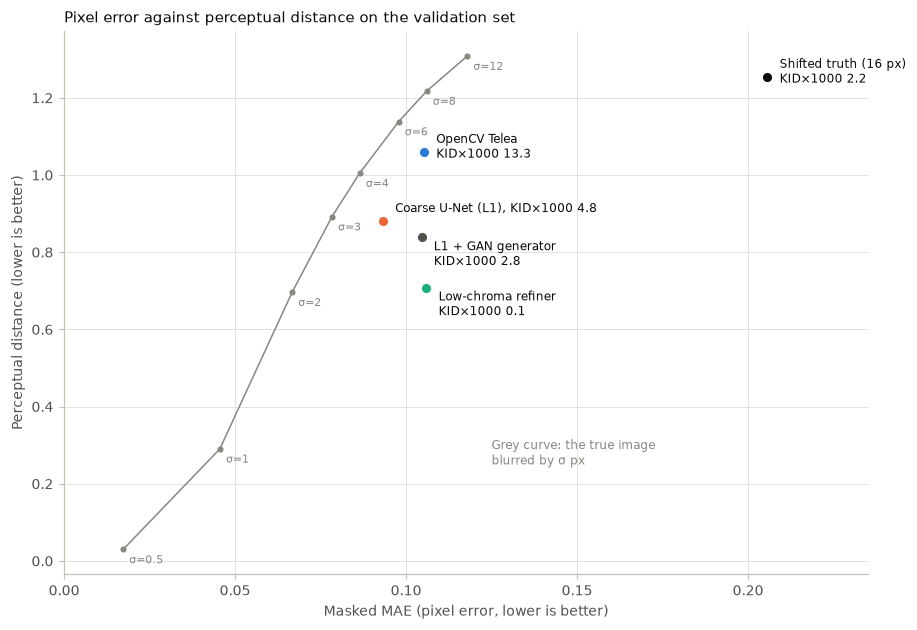

In [16]:
diagnostics = pd.read_csv(RECORD_DIR / "diagnostics" / "metric_summary.csv", index_col="method")
refinement = pd.read_csv(RECORD_DIR / "refinement" / "metric_summary.csv", index_col="method")
followup = pd.read_csv(RECORD_DIR / "refinement_followup" / "metric_summary.csv", index_col="method")
oracles = diagnostics[diagnostics.index.str.startswith("Blurred truth")]

fig, ax = plt.subplots(figsize=(8.5, 5.8))
ax.plot(oracles["masked_mae"], oracles["feature_distance"], "-", color=MUTED_INK, linewidth=1)
for name, row in oracles.iterrows():
    ax.plot(row["masked_mae"], row["feature_distance"], "o", color=MUTED_INK, markersize=3)
    ax.annotate(name.replace("Blurred truth ", ""), (row["masked_mae"], row["feature_distance"]),
                textcoords="offset points", xytext=(4, -9), fontsize=7, color=MUTED_INK)
ax.text(0.125, 0.25, "Grey curve: the true image\nblurred by σ px", color=MUTED_INK, fontsize=8)
shifted = diagnostics.loc["Shifted truth (16 px)"]
points = [
    ("OpenCV Telea", diagnostics.loc["OpenCV Telea"], METHOD_COLORS["OpenCV Telea"]),
    ("Coarse U-Net (L1)", diagnostics.loc["Deep U-Net (MAE reference)"], METHOD_COLORS["Coarse U-Net"]),
    ("L1 + GAN generator", diagnostics.loc["L1 + GAN (1,500 updates)"], SECONDARY_INK),
    ("Low-chroma refiner", followup.loc["Low-chroma refiner"], METHOD_COLORS["Low-chroma refiner"]),
    ("Shifted truth (16 px)", shifted, INK),
]
offsets = {}
for label, row, color in points:
    ax.plot(row["masked_mae"], row["feature_distance"], "o", color=color, markersize=7,
            markeredgecolor="white", markeredgewidth=1)
    one_line = label.startswith("Coarse")       # avoids the L1 + GAN label just below
    ax.annotate(f"{label}{', ' if one_line else chr(10)}KID×1000 {row['kid_x1000']:.1f}",
                (row["masked_mae"], row["feature_distance"]), textcoords="offset points",
                xytext=(8, 6) if one_line else (8, -18) if label.startswith(("L1", "Low")) else (8, -4),
                fontsize=8)
ax.set_xlabel("Masked MAE (pixel error, lower is better)")
ax.set_ylabel("Perceptual distance (lower is better)")
ax.grid(axis="x")
ax.set_xlim(0, 0.235)
ax.set_title("Pixel error against perceptual distance on the validation set", loc="left")
plt.tight_layout()
plt.show()

**Reading the figure.** Each point is a set of 400 validation fills.

- **The grey curve:** the true image blurred more and more. Moving right
  along it means more pixel error and less detail.
- **The U-Net:** it sits on that curve between σ = 4 and σ = 6. It behaves
  like a blurred version of the truth.
- **The second L1 network:** not drawn, because it lands on the same spot
  (masked MAE 0.0930, perceptual distance 0.876).
- **The models trained for texture** (L1 + GAN, then our refiner): they move
  *down*, to a much lower perceptual distance, at the cost of a small move
  *right*, a slightly higher masked MAE.
- **The shifted truth:** far right and low. It is the extreme case: perfect
  texture in the wrong place.

The low-chroma refiner has the lowest perceptual distance and a KID close
to zero. It is the model we kept.

## 7. Prediction (`model.predict`)

Both trained stages are applied to the 400 test images:

- the U-Net with `coarse_unet.predict`;
- the complete model with `two_stage.predict`.

Every result keeps the original pixels outside the hole. The predictions
must equal those made by the package code used in the test evaluation
(`03_evaluation.ipynb`), which this notebook re-checks in Section 8.

The app's chain (our model followed by the diffusion model) and the
diffusion model alone take 8 and 11 seconds per image. Their test results
were computed once and cached in `models/test_evaluation/`, and they are
read from there.

Predicted 400 test images with both stages in 4.5 s
Largest difference from the package predictions: coarse 0.0e+00, refined 1.2e-07


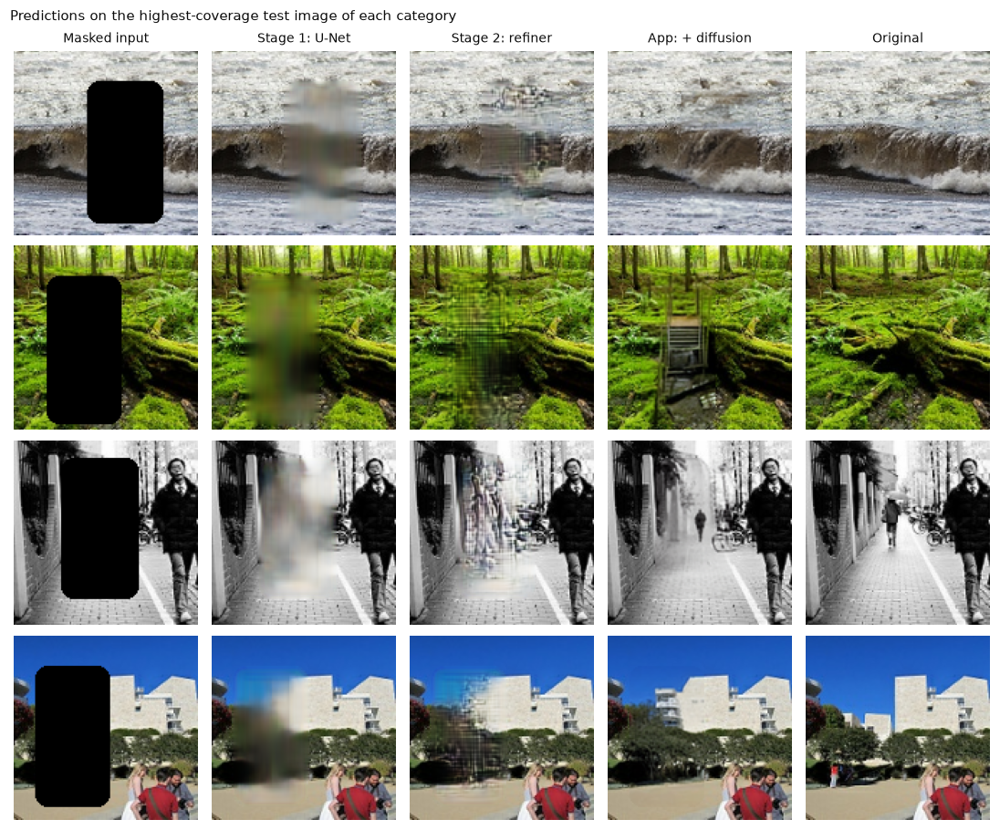

In [17]:
start = time.perf_counter()
coarse_results = test_set.compose(coarse_unet.predict(test_set.inputs, batch_size=16, verbose=0))
refined_results = two_stage.predict(test_set.inputs, batch_size=16, verbose=0)
prediction_seconds = time.perf_counter() - start

# The same predictions through the package functions used in 03_evaluation.ipynb.
package_coarse = predict_coarse(saved_coarse, test_set)
package_refined = refine_images(saved_refiner, package_coarse, test_set.masks, package_refine)
print(f"Predicted 400 test images with both stages in {prediction_seconds:.1f} s")
print(f"Largest difference from the package predictions: coarse "
      f"{np.abs(coarse_results - package_coarse).max():.1e}, refined "
      f"{np.abs(refined_results - package_refined).max():.1e}")
assert np.abs(refined_results - package_refined).max() < 1e-4

reconstructions = {
    "OpenCV Telea": opencv_telea(test_set),
    "Coarse U-Net": package_coarse,
    "Low-chroma refiner": package_refined,
}
cached_seconds = {}
for name, file in [("Pretrained diffusion", "pretrained_diffusion.npz"),
                   ("Our model + diffusion", "our_model_and_diffusion.npz")]:
    cached = np.load(CACHE_DIR / file)
    reconstructions[name] = test_set.compose(cached["images"].astype(np.float32) / 255)
    cached_seconds[name] = float(cached["seconds_per_image"])
log_memory("Test predictions done")

examples = test_set.example_indices()
fig, axes = plt.subplots(len(examples), 5, figsize=(10, 8.4))
columns = [("Masked input", test_set.visible), ("Stage 1: U-Net", package_coarse),
           ("Stage 2: refiner", package_refined), ("App: + diffusion", reconstructions["Our model + diffusion"]),
           ("Original", test_set.originals)]
for row, index in enumerate(examples):
    for col, (title, images) in enumerate(columns):
        ax = axes[row, col]
        ax.imshow(np.clip(images[index], 0, 1))
        ax.axis("off")
        if row == 0:
            ax.set_title(title, fontsize=9)
fig.suptitle("Predictions on the highest-coverage test image of each category", x=0.01,
             ha="left", fontsize=10)
plt.tight_layout()
plt.show()

From left to right, each stage adds what the previous one lacked.

- **The U-Net:** it places the right colours and the horizon, but the fill
  is smooth.
- **The refiner:** it adds texture with the character of the surroundings
  (waves, foliage, paving). It also shows faint blocky patterns, discussed
  in Section 9.
- **The diffusion stage:** it turns that sketch into photographic detail. It
  can also invent content, such as the ladder-like object in the forest
  image.

## 8. Evaluation (`model.evaluate` and the Test Metrics)

### 8.1 Keras `evaluate`

The Keras models are compiled with the masked MAE and evaluated on the test
set.

`evaluate` averages the loss over batches of 16, so images in batches with
large holes weigh less than with a per-image average. The per-image masked
MAE in Section 8.2 is therefore slightly different. Section 8.2's version is
the one used for every comparison.

In [18]:
targets = np.concatenate([test_set.originals, test_set.masks], axis=-1)
keras_scores = {}
for name, model in [("Coarse U-Net", coarse_unet), ("Two-stage model (refiner)", two_stage)]:
    model.compile(loss=masked_mae, jit_compile=False)
    keras_scores[name] = model.evaluate(test_set.inputs, targets, batch_size=16, verbose=0)
display(pd.Series(keras_scores, name="masked MAE from model.evaluate").round(4).to_frame())

,masked MAE from model.evaluate
Coarse U-Net,0.0943
Two-stage model (refiner),0.1073


### 8.2 Every method on every measure

The five methods are scored with the measures of Section 3:

1. **OpenCV Telea:** the classical baseline, with no learning (Telea, 2004).
2. **Coarse U-Net:** our stage 1 alone.
3. **Low-chroma refiner:** our final model, stages 1 and 2.
4. **Pretrained diffusion:** Stable Diffusion 1.5 Inpainting alone, at
   strength 1, where it ignores our fill.
5. **Our model + diffusion:** the app's chain, at strength 0.7.

All are measured at 128 × 128.

Paired comparisons give the image-by-image difference between two methods,
with a 95% bootstrap interval over images.

Every table is recomputed here and checked against the tables frozen when
the test set was evaluated (`records/.../test/`). A difference larger than
$10^{-6}$ would stop the notebook.

In [19]:
evaluator = Evaluator(test_set)
evaluations = {name: evaluator.evaluate(reconstructions[name]) for name in METHODS}
log_memory("Test metrics computed")


def grid_by_period(images):
    table = pd.DataFrame(evaluator.grid_periodicity(images)).set_index("direction")
    return {f"grid {period} px ({direction[0]})": table.loc[direction, f"period {period} px"]
            for period in [2, 4] for direction in ["horizontal", "vertical"]}


metric_summary = pd.DataFrame({n: evaluations[n].summary() for n in METHODS}).T.rename_axis("method")
texture = pd.DataFrame({
    name: {**evaluator.detail_summary(images), **grid_by_period(images)}
    for name, images in {"True image": test_set.originals, **reconstructions}.items()
}).T.rename_axis("method")
PAIRS = [("Coarse U-Net", "OpenCV Telea"), ("Low-chroma refiner", "OpenCV Telea"),
         ("Low-chroma refiner", "Coarse U-Net"), ("Our model + diffusion", "Low-chroma refiner"),
         ("Our model + diffusion", "Pretrained diffusion")]
paired = pd.DataFrame([
    {"method": m, "baseline": b, **evaluator.paired(evaluations[m], evaluations[b])}
    for m, b in PAIRS
]).set_index(["method", "baseline"])
by_category = pd.DataFrame([
    {"method": name, "category": category,
     "masked_mae": evaluations[name].masked_mae[categories == category].mean(),
     "feature_distance": evaluations[name].feature_distance[categories == category].mean()}
    for name in METHODS for category in test_set.manifest["category"].unique()
]).set_index(["method", "category"])
NEAR_DUPLICATES = ["data/intel-image-classification/seg_test/seg_test/forest/22993.jpg"]
keep = ~test_set.manifest["path"].isin(NEAR_DUPLICATES).to_numpy()
without_duplicates = pd.DataFrame({
    name: {"masked_mae": evaluations[name].masked_mae[keep].mean(),
           "feature_distance": evaluations[name].feature_distance[keep].mean()}
    for name in METHODS
}).T.rename_axis("method")

for table, filename in [(metric_summary, "metric_summary.csv"), (texture, "texture_and_grid.csv"),
                        (paired, "paired_comparisons.csv"), (by_category, "category_summary.csv"),
                        (without_duplicates, "summary_without_near_duplicates.csv")]:
    print(f"{filename}: {save_or_check(table, TEST_RECORD_DIR / filename)}")

main_table = metric_summary[["masked_mae", "feature_distance", "kid_x1000", "kid_x1000_std"]].rename(
    columns={"masked_mae": "masked MAE", "feature_distance": "perceptual distance",
             "kid_x1000": "KID × 1000", "kid_x1000_std": "KID std"})
display(main_table.round(4))
paired_view = paired.iloc[:, :6].round(4)
paired_view.columns = ["MAE Δ", "MAE 95% CI", "MAE: images better", "perceptual Δ",
                       "perceptual 95% CI", "perceptual: images better"]
paired_view["KID×1000 Δ (subsets lower)"] = [
    f"{delta:+.2f} ({share})" for delta, share in zip(paired["KID×1000 Δ"], paired["KID subsets lower"])]
display(paired_view)

metric_summary.csv: reproduced
texture_and_grid.csv: reproduced
paired_comparisons.csv: reproduced
category_summary.csv: reproduced
summary_without_near_duplicates.csv: reproduced


,masked MAE,perceptual distance,KID × 1000,KID std
method,,,,
OpenCV Telea,0.1049,1.0848,15.2161,3.5677
Coarse U-Net,0.0915,0.8842,5.9868,2.3286
Low-chroma refiner,0.1043,0.7142,0.3676,1.9627
Pretrained diffusion,0.1380,0.8221,-0.6172,1.9962
Our model + diffusion,0.1027,0.5957,-1.5482,1.8853


MAE Δ          MAE 95% CI  \
method                baseline                                           
Coarse U-Net          OpenCV Telea         -0.0134  [-0.0150, -0.0119]   
Low-chroma refiner    OpenCV Telea         -0.0006  [-0.0023, +0.0011]   
                      Coarse U-Net          0.0128  [+0.0119, +0.0138]   
Our model + diffusion Low-chroma refiner   -0.0016  [-0.0033, -0.0000]   
                      Pretrained diffusion -0.0352  [-0.0407, -0.0303]   

                                           MAE: images better  perceptual Δ  \
method                baseline                                                
Coarse U-Net          OpenCV Telea                        88%       -0.2006   
Low-chroma refiner    OpenCV Telea                        48%       -0.3706   
                      Coarse U-Net                         5%       -0.1699   
Our model + diffusion Low-chroma refiner                  48%       -0.1185   
                      Pretrained diffusion                86%       -0.2263   

                                             perceptual 95% CI  \
method                baseline                                   
Coarse U-Net          OpenCV Telea          [-0.2183, -0.1830]   
Low-chroma refiner    OpenCV Telea          [-0.3970, -0.3456]   
                      Coarse U-Net          [-0.1848, -0.1549]   
Our model + diffusion Low-chroma refiner    [-0.1357, -0.1019]   
                      Pretrained diffusion  [-0.2730, -0.1831]   

                                           perceptual: images better  \
method                baseline                                         
Coarse U-Net          OpenCV Telea                               91%   
Low-chroma refiner    OpenCV Telea                               96%   
                      Coarse U-Net                               90%   
Our model + diffusion Low-chroma refiner                         76%   
                      Pretrained diffusion                       75%   

                                           KID×1000 Δ (subsets lower)  
method                baseline                                         
Coarse U-Net          OpenCV Telea                       -9.23 (100%)  
Low-chroma refiner    OpenCV Telea                      -14.85 (100%)  
                      Coarse U-Net                       -5.62 (100%)  
Our model + diffusion Low-chroma refiner                  -1.92 (99%)  
                      Pretrained diffusion                -0.93 (88%)

## 9. Interpretation of the Results

### 9.1 Pixel error against perceptual quality

Each method is plotted at its mean masked MAE and perceptual distance on the
test set, as in Section 6.3. Lower-left is better on both.

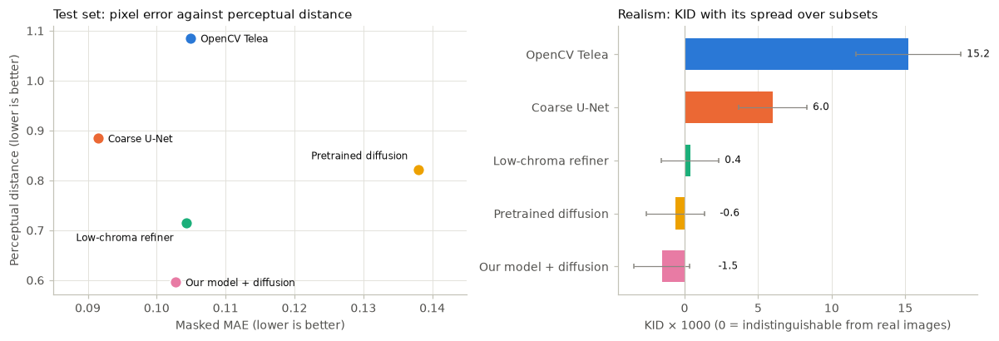

In [20]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8), gridspec_kw={"width_ratios": [1.15, 1]})
ax = axes[0]
offsets = {"OpenCV Telea": (8, -3), "Coarse U-Net": (8, -3), "Low-chroma refiner": (-10, -14),
           "Pretrained diffusion": (-8, 8), "Our model + diffusion": (8, -3)}
for name in METHODS:
    row = metric_summary.loc[name]
    ax.plot(row["masked_mae"], row["feature_distance"], "o", color=METHOD_COLORS[name],
            markersize=9, markeredgecolor="white", markeredgewidth=1)
    ax.annotate(name, (row["masked_mae"], row["feature_distance"]), textcoords="offset points",
                xytext=offsets[name], fontsize=8,
                ha="right" if offsets[name][0] < 0 else "left")
ax.set_xlabel("Masked MAE (lower is better)")
ax.set_ylabel("Perceptual distance (lower is better)")
ax.grid(axis="x")
ax.set_xlim(0.085, 0.145)
ax.set_title("Test set: pixel error against perceptual distance", loc="left")

ax = axes[1]
values = metric_summary.loc[METHODS, "kid_x1000"]
errors = metric_summary.loc[METHODS, "kid_x1000_std"]
bars = ax.barh(range(len(METHODS)), values, xerr=errors, color=[METHOD_COLORS[n] for n in METHODS],
               height=0.6, error_kw={"ecolor": MUTED_INK, "elinewidth": 0.8, "capsize": 2})
ax.set_yticks(range(len(METHODS)), METHODS)
ax.invert_yaxis()
ax.axvline(0, color=LIGHT_GRAY, linewidth=0.8)
for y, value in enumerate(values):
    ax.text(max(value, 0) + errors.iloc[y] + 0.4, y, f"{value:.1f}", va="center", fontsize=8)
ax.grid(axis="x"); ax.grid(axis="y", visible=False)
ax.set_xlabel("KID × 1000 (0 = indistinguishable from real images)")
ax.set_title("Realism: KID with its spread over subsets", loc="left")
plt.tight_layout()
plt.show()

**Reading the figure.**

- **Left: pixel error against perceptual distance.**
  - The U-Net has the lowest pixel error (0.092) but a high perceptual
    distance.
  - The refiner moves down: perceptual distance falls from 0.884 to 0.714,
    while pixel error rises to the level of OpenCV.
  - The diffusion model alone is far to the right (0.138). It invents
    convincing content that does not match what was hidden.
  - Our model + diffusion is the lowest point of all (0.596) and keeps the
    refiner's pixel error.
- **Right: realism (KID).**
  - OpenCV (15.2) and the U-Net (6.0) are clearly distinguishable from real
    images.
  - The other three methods are within one standard deviation of zero.
    With 400 images, their results cannot be told apart from real photos by
    this measure.

### 9.2 The four questions, answered with paired comparisons

The four questions below were fixed before the test run. A difference
counts only if:

- its 95% interval excludes zero;
- between our trained models, it is also larger than the 0.004 masked MAE
  that separates two training runs.

1. **Do our models beat OpenCV?** Yes.
   - **The U-Net** is better on all three measures:
     - masked MAE −0.0134 (95% CI [−0.0150, −0.0119]), lower on 88% of
       images;
     - perceptual distance −0.201, lower on 91% of images;
     - KID lower in every subset.
   - **The refiner** is much better on perceptual distance (−0.371, lower
     on 96% of images) and on KID (−14.8). Its masked MAE does not differ
     ([−0.0023, +0.0011]).
2. **What does the refiner change relative to the U-Net?** It trades pixel
   error for perceptual quality.
   - Masked MAE rises by 0.0128 ([+0.0119, +0.0138]): three times the
     run-to-run variation.
   - Perceptual distance falls by 0.170, lower on 90% of images.
   - This is the trade-off of Section 6.3, now confirmed on unseen data.
3. **What does the pretrained stage add to our model?**
   - Perceptual distance falls by a further 0.119 ([−0.136, −0.102]), lower
     on 76% of images, and KID is lower in 99% of subsets.
   - The masked MAE changes by −0.0016. Its interval, [−0.0033, −0.0000],
     barely excludes zero, and the change is below the run-to-run
     variation, so we count the pixel error as unchanged.
4. **Does our stage 1 help the pretrained model?** Yes, clearly. Starting
   from our fill instead of pure noise:
   - lowers masked MAE by 0.035 ([−0.041, −0.030]), lower on 86% of images;
   - lowers perceptual distance by 0.226 ([−0.273, −0.183]).

   Our model contributes the right content, and the pretrained model the
   photographic detail.

### 9.3 Visual comparison

The highest-coverage test image of each category for every method, then
enlarged 48 × 48-pixel crops of the filled region. The crops are shown
without smoothing, so pixel-level artifacts stay visible.

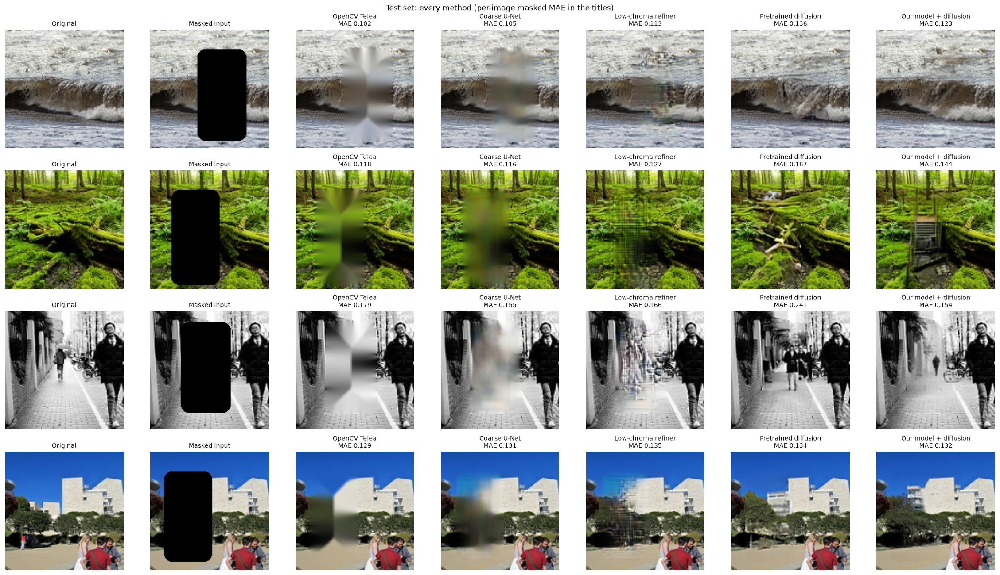

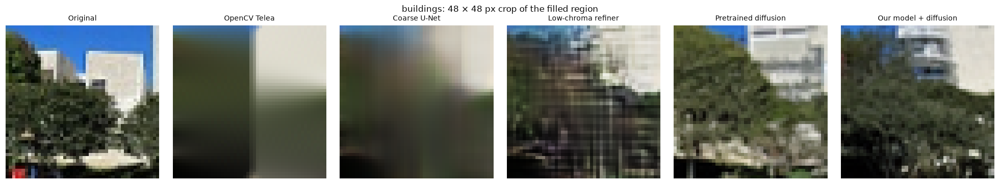

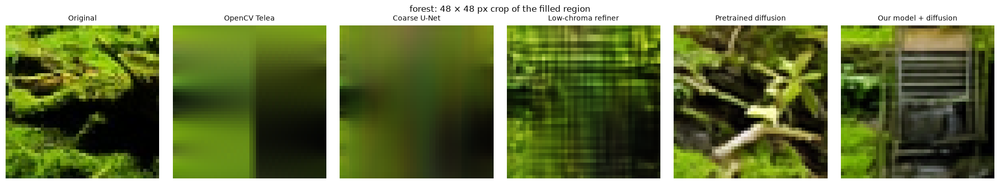

In [21]:
show_comparison(test_set, {name: reconstructions[name] for name in METHODS}, examples,
                "Test set: every method (per-image masked MAE in the titles)")
for category, index in zip(["buildings", "forest"], test_set.example_indices(["buildings", "forest"])):
    show_zoom(test_set, {name: reconstructions[name] for name in METHODS}, index,
              title=f"{category}: 48 × 48 px crop of the filled region")

The images confirm the measures:

- **OpenCV** smears the border colours inward.
- **The U-Net** produces a soft, correctly coloured blur.
- **The refiner** adds texture of the right kind (foam, foliage, facade
  detail), with a visible blocky pattern in the crops: the grid artifact of
  Section 5.
- **The diffusion stage** removes most of that grid. It can also invent
  structure. In the forest image the chain draws a ladder-like object
  where the refiner's fill had its strongest stripes. At strength 0.7, the
  pretrained model keeps part of our fill's structure, artifacts included.
- **The diffusion model alone** fills every hole with sharp but different
  content, for example several walkers where the original street had one.

### 9.4 Where the model struggles

Two properties of each test image predict how hard it is to fill:

- **hole coverage:** the share of the image hidden;
- **detail in the hole:** the fine-detail energy of the hidden region in the
  true image (Section 1.3).

The figure groups the 400 test images into quartiles of each property and
shows each method's mean masked MAE. The table gives Spearman rank
correlations between each property and the per-image error.

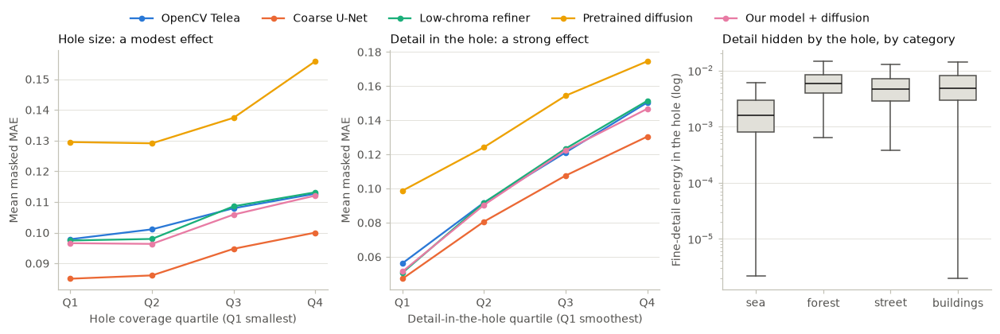

,hole coverage,detail in the hole
OpenCV Telea,0.15,0.83
Coarse U-Net,0.17,0.84
Low-chroma refiner,0.15,0.85
Pretrained diffusion,0.18,0.56
Our model + diffusion,0.15,0.83


masked_mae                         feature_distance  \
category               buildings  forest     sea  street        buildings   
method                                                                      
Coarse U-Net              0.1038  0.1016  0.0576  0.1029           0.8840   
Low-chroma refiner        0.1178  0.1185  0.0626  0.1183           0.7831   
OpenCV Telea              0.1184  0.1150  0.0696  0.1165           1.0450   
Our model + diffusion     0.1074  0.1201  0.0657  0.1177           0.5695   
Pretrained diffusion      0.1317  0.1605  0.1068  0.1529           0.6800   

                                               
category               forest     sea  street  
method                                         
Coarse U-Net           0.9922  0.7092  0.9514  
Low-chroma refiner     0.7163  0.5599  0.7977  
OpenCV Telea           1.1922  0.9880  1.1141  
Our model + diffusion  0.6585  0.4748  0.6802  
Pretrained diffusion   0.8498  0.8875  0.8709

In [22]:
analysis = pd.DataFrame({
    "category": categories,
    "coverage": test_set.masks.mean(axis=(1, 2, 3)),
    "hole detail": evaluator.truth_luma_detail,
    **{name: evaluations[name].masked_mae for name in METHODS},
})
analysis["coverage quartile"] = pd.qcut(analysis["coverage"], 4, labels=["Q1", "Q2", "Q3", "Q4"])
analysis["detail quartile"] = pd.qcut(analysis["hole detail"], 4, labels=["Q1", "Q2", "Q3", "Q4"])

fig, axes = plt.subplots(1, 3, figsize=(11.5, 3.6))
for ax, (quartile, label) in zip(axes[:2], [("coverage quartile", "Hole coverage quartile (Q1 smallest)"),
                                            ("detail quartile", "Detail-in-the-hole quartile (Q1 smoothest)")]):
    means = analysis.groupby(quartile, observed=True)[METHODS].mean()
    for name in METHODS:
        ax.plot(means.index.astype(str), means[name], "-o", color=METHOD_COLORS[name], markersize=4)
    ax.set_xlabel(label)
    ax.set_ylabel("Mean masked MAE")
axes[0].set_title("Hole size: a modest effect", loc="left")
axes[1].set_title("Detail in the hole: a strong effect", loc="left")
fig.legend([plt.Line2D([], [], color=METHOD_COLORS[n], marker="o", markersize=4) for n in METHODS],
           METHODS, loc="upper center", ncol=5, bbox_to_anchor=(0.5, 1.06))

ax = axes[2]
ax.boxplot([analysis.loc[analysis["category"] == c, "hole detail"] for c in CATEGORIES],
           tick_labels=CATEGORIES, widths=0.55, patch_artist=True, showfliers=False,
           boxprops={"facecolor": "#e1e0d9", "edgecolor": SECONDARY_INK},
           medianprops={"color": INK}, whiskerprops={"color": SECONDARY_INK},
           capprops={"color": SECONDARY_INK})
ax.set_yscale("log")
ax.set_ylabel("Fine-detail energy in the hole (log)")
ax.set_title("Detail hidden by the hole, by category", loc="left")
plt.tight_layout()
plt.show()

spearman = pd.DataFrame({
    name: {"hole coverage": analysis["coverage"].corr(analysis[name], method="spearman"),
           "detail in the hole": analysis["hole detail"].corr(analysis[name], method="spearman")}
    for name in METHODS
}).T
display(spearman.round(2))
display(by_category.unstack("category").round(4))

**What makes a hole hard.**

- **Detail is the strongest predictor of error.** How much fine detail the
  hidden region contains gives Spearman correlations of 0.83–0.85 with the
  error of OpenCV and of our models. From the smoothest to the most
  detailed quarter of holes, our models' error grows 2.7 to 3 times: from
  0.048 to 0.130 for the U-Net.
- **Hole size matters much less** (Spearman 0.15–0.18). From the smallest to
  the largest quarter of holes, the error grows by only 15–20%.
- **The diffusion model alone** follows the same pattern more weakly
  (0.56). Its error is dominated by invented content, whatever the scene.

**By category.**

- **Sea is the easiest scene for every method.** The U-Net's masked MAE is
  0.058 on sea, about half that of the other categories. Its holes hide about
  four times less detail (medians).
- **Forest, street, and buildings** have similar pixel errors (0.10–0.12).
- **Street is the hardest category for realism.** It has the highest
  perceptual distance for both our final model (0.798) and the app's chain
  (0.680). Street scenes contain things with precise geometry: people,
  cars, signs, and building edges in perspective. Their content often
  cannot be guessed from the surroundings, and texture alone does not make
  them look right.

The street images with the largest error for our final model show what goes
wrong.

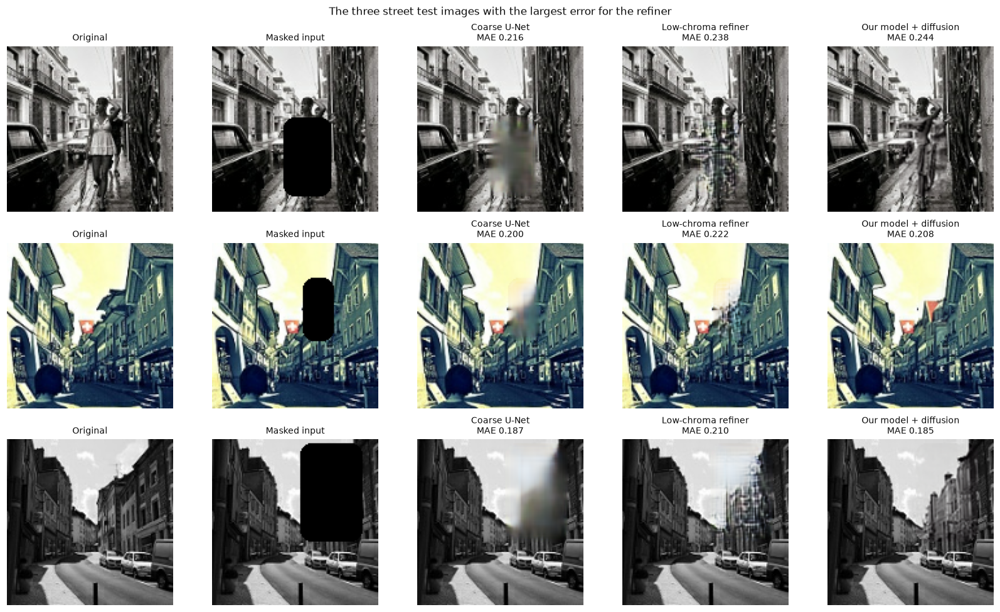

In [23]:
street = np.flatnonzero(categories == "street")
worst = street[np.argsort(evaluations["Low-chroma refiner"].masked_mae[street])[-3:][::-1]]
show_comparison(test_set, {name: reconstructions[name]
                           for name in ["Coarse U-Net", "Low-chroma refiner", "Our model + diffusion"]},
                list(worst), "The three street test images with the largest error for the refiner")

**Why these three fail.**

- **Image 1:** the hole hides a woman walking down the street.
- **Image 2:** it hides a flag and part of a facade.
- **Image 3:** it hides most of a row of buildings seen in perspective.

In each case, the error comes from content that no model could infer from
the surroundings, or from structure that must continue exactly:

- the U-Net blurs it;
- the refiner turns it into its blocky texture;
- the app's chain draws coherent but different buildings.

**The first image shows a limit of the measure itself.** The "truth"
contains a person, so a fill that shows only street is penalized. For a
tool whose purpose is to remove people, that fill is the desired result.
Pixel error against the original image is only a proxy for the goal.

### 9.5 Texture and the grid artifact

Fine-detail ratios compare the detail in each fill with the true image's
(1 = same amount, measured inside the hole). Grid components measure jumps
that repeat every 2 or 4 pixels at fixed positions. The true images' row
gives the level of a fill with no artifact.

In [24]:
detail_columns = ["luma_detail_ratio", "chroma_detail_ratio", "chroma_share", "images_chroma_over_2x"]
display(texture[detail_columns].rename(columns={
    "luma_detail_ratio": "luminance detail ratio", "chroma_detail_ratio": "colour detail ratio",
    "chroma_share": "colour share of detail", "images_chroma_over_2x": "images with > 2 × colour detail",
}).round(4))
display(texture.drop(columns=detail_columns).round(4))

,luminance detail ratio,colour detail ratio,colour share of detail,images with > 2 × colour detail
method,,,,
True image,1.0000,1.0000,0.0105,0.0000
OpenCV Telea,0.0221,0.1651,0.0822,0.0191
Coarse U-Net,0.0275,0.3079,0.1034,0.0929
Low-chroma refiner,0.8084,1.1033,0.0132,0.2377
Pretrained diffusion,0.7446,1.0596,0.0150,0.1858
Our model + diffusion,0.4706,0.7867,0.0179,0.0574


,grid 2 px (h),grid 2 px (v),grid 4 px (h),grid 4 px (v)
method,,,,
True image,0.0012,0.0021,0.0013,0.0052
OpenCV Telea,0.0018,0.0001,0.0028,0.0019
Coarse U-Net,0.0802,0.0603,0.0105,0.0041
Low-chroma refiner,0.0271,0.0280,0.0061,0.0098
Pretrained diffusion,0.0071,0.0147,0.0047,0.0021
Our model + diffusion,0.0070,0.0124,0.0018,0.0013


**What the table shows.**

- **Detail.** The refiner restores most of the fine detail the U-Net lacks:
  luminance ratio 0.81 against 0.03.
- **Colour.** Its colour detail is close to the truth's (1.10), the result
  of the low-chroma constraint.
- **Grid.** Its 2-pixel grid components, 0.027–0.028, are still more than
  ten times those of real images.

Polishing this mosaic was the hardest part of the project. It took several
controlled training runs of 3,000 updates each, testing three causes:

1. **The style weight:** ruled out (Section 5).
2. **The decoder's nearest-neighbour upsampling:** a known source of
   checkerboard patterns (Odena et al., 2016).
3. **The fixed alignment of the networks that compute the losses.**

A second training seed then showed that the grid varies between two runs of
the same model almost as much as between the variants. It also showed that
part of the 2-pixel grid is inherited from the U-Net's own upsampling. No
variant beat the low-chroma refiner reliably, so we kept it.

In the app, the diffusion stage reduces the 2-pixel components to the level
of the diffusion model alone, and the 4-pixel ones to that of real images.
It also reduces the images with excess colour detail from 24% to 6%. The
cost is fine detail: the luminance ratio falls from 0.81 to 0.47.

### 9.6 Do the validation results carry over to the test set?

All models and settings were chosen on the validation set. If that choice
had overfitted the validation images, the test results would be worse.

In [25]:
validation_results = pd.concat([
    followup.loc[["Deep U-Net (MAE reference)", "Low-chroma refiner"]],
    diagnostics.loc[["OpenCV Telea"]],
])[["masked_mae", "feature_distance", "kid_x1000"]]
validation_results.index = ["Coarse U-Net", "Low-chroma refiner", "OpenCV Telea"]
comparison = pd.concat({"validation": validation_results,
                        "test": metric_summary.loc[validation_results.index,
                                                   ["masked_mae", "feature_distance", "kid_x1000"]]},
                       axis=1).swaplevel(axis=1).sort_index(axis=1, level=0, sort_remaining=False)
display(comparison.round(4))

feature_distance          kid_x1000          masked_mae  \
                         validation    test validation     test validation   
Coarse U-Net                 0.8803  0.8842     4.7893   5.9868     0.0932   
Low-chroma refiner           0.7083  0.7142     0.0677   0.3676     0.1059   
OpenCV Telea                 1.0610  1.0848    13.3130  15.2161     0.1053   

                            
                      test  
Coarse U-Net        0.0915  
Low-chroma refiner  0.1043  
OpenCV Telea        0.1049

The test values are within 0.002 of the validation values in masked MAE
and within 0.025 in perceptual distance. The refiner-versus-U-Net
difference is almost identical:

- **validation:** +0.0127 masked MAE and −0.172 perceptual distance;
- **test:** +0.0128 and −0.170.

Choosing the models on the validation set did not overfit them to it.

Two further checks:

- **Near-duplicate.** One test image (`forest/22993.jpg`) shows the same
  scene as a validation image. Removing it changes no masked MAE by more
  than 0.0001.
- **Exact duplicates.** No test file is identical to a training or
  validation file.

## 10. Compute, Memory, and Run Time

All training and evaluation ran on one laptop:

- **Machine:** an Apple MacBook with the M5 chip.
- **GPU:** TensorFlow uses its integrated GPU through Apple's Metal plugin.
- **Memory:** CPU and GPU share 16 GB of unified memory, so there is no
  separate GPU memory to report.

The published app runs on a Hugging Face Space:

- **Stage 1** on the CPU;
- **The diffusion stage** on a ZeroGPU slice, a shared NVIDIA GPU attached
  only for that call.

In [26]:
try:
    chip = subprocess.run(["sysctl", "-n", "machdep.cpu.brand_string"], capture_output=True,
                          text=True, check=True).stdout.strip()
except (OSError, subprocess.CalledProcessError):
    chip = platform.processor()
hardware = pd.Series({
    "Chip": chip,
    "CPU cores": psutil.cpu_count(logical=False),
    "Unified memory (GiB)": round(psutil.virtual_memory().total / 2 ** 30, 1),
    "Operating system": platform.platform(terse=True),
    "Python": platform.python_version(),
    "TensorFlow / Keras": f"{tf.__version__} / {keras.__version__}",
    "GPU devices seen by TensorFlow": ", ".join(d.name for d in tf.config.list_physical_devices("GPU")),
}, name="value").to_frame()
display(hardware)

two_stage.predict(test_set.inputs[:16], verbose=0)                 # warm-up
start = time.perf_counter()
two_stage.predict(test_set.inputs, batch_size=50, verbose=0)
batched = (time.perf_counter() - start) / len(test_set)
single = []
for index in range(20):
    start = time.perf_counter()
    two_stage(tf.constant(test_set.inputs[index:index + 1]), training=False).numpy()
    single.append(time.perf_counter() - start)
log_memory("Timing done")

timing = pd.DataFrame([
    {"task": "Expanded-context U-Net, 20 epochs on 2,000 images", "time": "23.6 min", "source": "01_training"},
    {"task": "Deeper U-Net, 20 epochs on 6,000 images", "time": "79.2 min", "source": "01_training"},
    {"task": "Refiner run: 3,000 updates of two refiners and a discriminator",
     "time": "≈ 90 min (1.8 s per update)", "source": "01_training (pilot timing)"},
    {"task": "Our two stages, per image in batches of 50 (Metal GPU)", "time": f"{batched * 1000:.1f} ms",
     "source": "measured here"},
    {"task": "Our two stages, one image at a time", "time": f"{np.median(single) * 1000:.0f} ms",
     "source": "measured here (median of 20)"},
    {"task": "Diffusion alone, 30 steps at 512 px, per image (Metal GPU)",
     "time": f"{cached_seconds['Pretrained diffusion']:.1f} s", "source": "03_evaluation"},
    {"task": "Our model + diffusion, 21 steps, per image (Metal GPU)",
     "time": f"{cached_seconds['Our model + diffusion']:.1f} s", "source": "03_evaluation"},
    {"task": "One removal in the published app (ZeroGPU)", "time": "6–7 s", "source": "measured on the Space"},
]).set_index("task")
display(timing)

sizes = pd.DataFrame([
    {"network": "Coarse U-Net", "role": "trained here, inference",
     "parameters": f"{coarse_unet.count_params():,}",
     "file size (MB)": round((MODEL_DIR / COARSE_MODEL_FILE).stat().st_size / 1e6, 1)},
    {"network": "Low-chroma refiner", "role": "trained here, inference",
     "parameters": f"{refiner.count_params():,}",
     "file size (MB)": round((MODEL_DIR / refiner_file).stat().st_size / 1e6, 1)},
    {"network": "SN-PatchGAN discriminator", "role": "trained here, training only",
     "parameters": f"{discriminator.count_params():,}", "file size (MB)": None},
    {"network": "VGG16 (to block3_pool)", "role": "pretrained, frozen loss network",
     "parameters": f"{loss_features.count_params():,}", "file size (MB)": None},
    {"network": "Stable Diffusion 1.5 Inpainting", "role": "pretrained, app only",
     "parameters": "about 1 billion", "file size (MB)": 2100},
]).set_index("network")
display(sizes)
display(pd.Series(memory_log, name="process memory (GB)").round(2).to_frame())
print(f"This notebook ran in {(time.perf_counter() - NOTEBOOK_START) / 60:.1f} minutes.")

,value
Chip,Apple M5
CPU cores,10
Unified memory (GiB),16.0
Operating system,macOS-26.6.2
Python,3.12.13
TensorFlow / Keras,2.18.1 / 3.15.1
GPU devices seen by TensorFlow,/physical_device:GPU:0


,time,source
task,,
"Expanded-context U-Net, 20 epochs on 2,000 images",23.6 min,01_training
"Deeper U-Net, 20 epochs on 6,000 images",79.2 min,01_training
"Refiner run: 3,000 updates of two refiners and a discriminator",≈ 90 min (1.8 s per update),01_training (pilot timing)
"Our two stages, per image in batches of 50 (Metal GPU)",8.5 ms,measured here
"Our two stages, one image at a time",50 ms,measured here (median of 20)
"Diffusion alone, 30 steps at 512 px, per image (Metal GPU)",10.9 s,03_evaluation
"Our model + diffusion, 21 steps, per image (Metal GPU)",7.9 s,03_evaluation
One removal in the published app (ZeroGPU),6–7 s,measured on the Space


,role,parameters,file size (MB)
network,,,
Coarse U-Net,"trained here, inference","3,321,155",40.0
Low-chroma refiner,"trained here, inference","2,018,403",8.2
SN-PatchGAN discriminator,"trained here, training only","2,672,514",NaN
VGG16 (to block3_pool),"pretrained, frozen loss network","1,735,488",NaN
Stable Diffusion 1.5 Inpainting,"pretrained, app only",about 1 billion,2100.0


,process memory (GB)
Libraries imported,0.58
Dataset statistics computed,0.64
Validation and test sets loaded,1.38
Models built,2.25
Test predictions done,2.15
Test metrics computed,1.39
Timing done,1.91


This notebook ran in 1.2 minutes.


**Training cost.** Training dominated the project's compute.

- The final U-Net took about 80 minutes, plus fine-tuning.
- Each refiner experiment took about 1.5 hours per pair of refiners.
- The refinement phase needed five such experiments.

**Inference speed.**

- **Our two stages:** about 10 ms per image in batches and 50 ms for a
  single image on the laptop GPU, fast enough for interactive use.
- **The diffusion stage:** it dominates the app's response time, at 7.9 s
  per image on the laptop and 6–7 s on the Space.

**Memory.**

- **This notebook:** the process peaked at about 2.6 GB with the test
  images, both models, VGG16, and InceptionV3 loaded.
- **Model files:** our two models take 48 MB on disk. The U-Net file is
  larger than its 3.3 M parameters suggest because it also stores the
  optimizer state.
- **Training:** with batches of 16 images at 128 × 128, memory was never a
  constraint. We did not log the peak memory of the training runs.

## 11. Next Steps

The results point to two directions:

- better photo quality;
- a more accurate reconstruction of the background.

**Higher resolution and photo quality.**

- **Train at 256 or 512 px on a higher-resolution dataset.** At 128 × 128,
  fine detail is beyond what our model can represent. The diffusion stage
  supplies it today. A larger training resolution would let our own model
  produce it.
- **Fourier convolutions, as in LaMa (Suvorov et al., 2022).** They give
  every layer a receptive field covering the whole image. They are designed
  for large masks and repetitive structures such as facades and fences,
  which are exactly our hardest cases, and they transfer across
  resolutions.
- **Fine-tune or distil the diffusion stage on our domain.** This could
  remove its tendency to add objects to the hole, and shorten its 21 steps.

**More accurate reconstruction of the background.**

- **Remove the grid at its source.** The 2-pixel component is inherited
  from the U-Net's nearest-neighbour upsampling. A U-Net retrained with
  bilinear or resize-convolution upsampling (Odena et al., 2016) is the
  direct test.
- **Attention to distant context.** Contextual attention (Yu et al., 2018)
  copies texture from matching patches elsewhere in the image. That would
  help where the background repeats: street paving, building windows.
- **Structure first, texture second.** Predicting edges or line structure
  before colours would keep straight lines straight across large holes.

**Evaluation.**

- **Several training seeds per variant,** so the confidence intervals also
  cover the randomness of training.
- **A blind human study,** with pages prepared as in the training notebook,
  to check that the measured perceptual gains match human preference.

## 12. Lessons Learned

1. **The loss defines what the model learns.** An L1 loss on an ill-posed
   task produces the average of the plausible answers, which is a blur.
   Choosing measures of both fidelity and realism early would have pointed
   to the right objective sooner.
2. **Diagnose before scaling.** A larger model and three times the data
   gave 4%. Three cheap diagnostics (memorizing four images, comparing the
   training and validation error, and the blurred-truth oracles) showed
   why, and changed the plan.
3. **Compare against matched controls.** Training two variants from the
   same weights on the same batches made small effects measurable. It also
   separated the effect of a new loss from the effect of simply adding a
   second network.
4. **Single runs are noisy.** A second seed reversed a result that one run
   had supported: two runs of the same model differed by 0.004 in masked
   MAE. A difference smaller than that is not a finding.
5. **Measure an artifact before trying to fix it.** The colour fringing was
   fixed quickly once a colour-detail ratio made it visible in numbers. The
   mosaic required a dedicated grid measure, and even then several causes
   overlapped.
6. **Protect the test set.** Freezing the splits, masks, and result tables,
   and using the test images once, made the final numbers trustworthy. The
   validation results carried over almost exactly.
7. **Pretrained models complement a small model rather than replacing it.**
   Our model decides what belongs in the hole. The pretrained model adds
   photographic detail. Together they beat either one alone.
8. **Engineering is part of the work:**
   - resumable checkpoints for multi-hour runs;
   - cached results for slow evaluations;
   - workarounds for operations without Metal GPU kernels;
   - splitting the app so that only the diffusion stage needs a GPU.

## 13. Summary Report

**Problem.** Remove an object painted by the user from a photo and fill
the region with a plausible background, without changing the rest of the
image.

**Data.** Intel Image Classification, four scene categories, images
resized to 128 × 128 and normalized to [0, 1].

| Split | Images | Source | Masks |
| --- | --- | --- | --- |
| Training | 6,000 | `seg_train` | random masks (strokes, blocks, person silhouettes), new in every batch |
| Validation | 400 | `seg_train`, disjoint from training | fixed |
| Test | 400 | `seg_test`, used once | fixed |

**Method.**

- **Stage 1, coarse U-Net:** 3.3 M parameters, dilated bottleneck, dropout,
  trained with masked MAE.
- **Stage 2, low-chroma refiner:** 2.0 M parameters, gated convolutions,
  trained with L1, perceptual, style, and adaptive adversarial losses
  against an SN-PatchGAN. Its detail is constrained to luminance.
- **App:** a pretrained Stable Diffusion 1.5 Inpainting model completes our
  fill at 512 px.
- **How the design evolved:** from a baseline through diagnostics. Measured
  limitations, not model size, drove each change.

**Results on the 400 test images** (lower is better):

| Method | Masked MAE | Perceptual distance | KID × 1000 |
| --- | --- | --- | --- |
| OpenCV Telea | 0.105 | 1.085 | 15.2 |
| Coarse U-Net (ours) | **0.092** | 0.884 | 6.0 |
| Low-chroma refiner (ours) | 0.104 | 0.714 | 0.4 |
| Pretrained diffusion alone | 0.138 | 0.822 | −0.6 |
| Our model + diffusion (app) | 0.103 | **0.596** | −1.5 |

**Conclusions.**

1. Both of our models beat the classical baseline on perceptual quality and
   realism. The U-Net also has lower pixel error.
2. The refiner trades a small increase in pixel error for a large gain in
   perceptual quality. Its results cannot be told apart from real images by
   KID.
3. Chaining it with the pretrained model gives the best perceptual result
   of all methods while keeping our pixel error. It is also clearly better
   than the pretrained model alone, which shows that our model contributes
   the right content.
4. The results agree with validation, so the model selection generalized.

**Limitations.**

- **Resolution.** Everything is measured at 128 × 128; the app works on
  photos of any size, where these figures apply only approximately.
- **Hard cases.** Large holes and detailed scenes (street, buildings) remain
  hard.
- **Residual grid.** A faint grid remains in the refiner's texture.
- **Inventions.** The diffusion stage sometimes invents objects.
- **Single training runs.** Each model was trained once.

**Assessment.** We are satisfied with the result. Starting from a model
that could only blur, we reached a two-stage model whose fills are
perceptually close to real images. We understand, and can measure, why each
design decision was taken. The app turns the model into a usable tool on
photos of any size, available online.

## 14. Contributions

*To be completed by the team: replace each name and adjust the areas to
what each member did. The course requires 5–7 members.*

| Member | Main contributions |
| --- | --- |
| [Name 1] | Dataset selection, preprocessing, and exploratory analysis (Sections 1–2) |
| [Name 2] | Baseline models, U-Net experiments, and diagnostics (Sections 5, 6.1, 6.3) |
| [Name 3] | Refiner design, losses, and adversarial training (Sections 4.2–4.3, 6.2) |
| [Name 4] | Artifact analysis and refinement experiments (Sections 5, 9.5) |
| [Name 5] | Evaluation metrics and the final test evaluation (Sections 8–9) |
| [Name 6] | Application, deployment, and the presentation (Section 4.4) |

## 15. References

- Bińkowski, M., Sutherland, D. J., Arbel, M., & Gretton, A. (2018).
  Demystifying MMD GANs. *ICLR*. arXiv:1801.01401.
- Blau, Y., & Michaeli, T. (2018). The perception-distortion tradeoff.
  *CVPR*. arXiv:1711.06077.
- Esser, P., Rombach, R., & Ommer, B. (2021). Taming transformers for
  high-resolution image synthesis. *CVPR*. arXiv:2012.09841.
- Gatys, L. A., Ecker, A. S., & Bethge, M. (2016). Image style transfer
  using convolutional neural networks. *CVPR*.
- Iizuka, S., Simo-Serra, E., & Ishikawa, H. (2017). Globally and locally
  consistent image completion. *ACM Transactions on Graphics, 36*(4).
- Isola, P., Zhu, J.-Y., Zhou, T., & Efros, A. A. (2017). Image-to-image
  translation with conditional adversarial networks. *CVPR*.
  arXiv:1611.07004.
- Johnson, J., Alahi, A., & Fei-Fei, L. (2016). Perceptual losses for
  real-time style transfer and super-resolution. *ECCV*. arXiv:1603.08155.
- Kingma, D. P., & Ba, J. (2015). Adam: A method for stochastic
  optimization. *ICLR*. arXiv:1412.6980.
- Liu, G., Reda, F. A., Shih, K. J., Wang, T.-C., Tao, A., & Catanzaro, B.
  (2018). Image inpainting for irregular holes using partial convolutions.
  *ECCV*. arXiv:1804.07723.
- Luo, W., Li, Y., Urtasun, R., & Zemel, R. (2016). Understanding the
  effective receptive field in deep convolutional neural networks.
  *NeurIPS*. arXiv:1701.04128.
- Mathieu, M., Couprie, C., & LeCun, Y. (2016). Deep multi-scale video
  prediction beyond mean square error. *ICLR*. arXiv:1511.05440.
- Meng, C., He, Y., Song, Y., Song, J., Wu, J., Zhu, J.-Y., & Ermon, S.
  (2022). SDEdit: Guided image synthesis and editing with stochastic
  differential equations. *ICLR*. arXiv:2108.01073.
- Miyato, T., Kataoka, T., Koyama, M., & Yoshida, Y. (2018). Spectral
  normalization for generative adversarial networks. *ICLR*.
  arXiv:1802.05957.
- Odena, A., Dumoulin, V., & Olah, C. (2016). Deconvolution and
  checkerboard artifacts. *Distill*. doi:10.23915/distill.00003.
- Pathak, D., Krähenbühl, P., Donahue, J., Darrell, T., & Efros, A. A.
  (2016). Context encoders: Feature learning by inpainting. *CVPR*.
  arXiv:1604.07379.
- Quan, W., Chen, J., Liu, Y., Yan, D.-M., & Wonka, P. (2024). Deep
  learning-based image and video inpainting: A survey. *International
  Journal of Computer Vision*. arXiv:2401.03395.
- Rombach, R., Blattmann, A., Lorenz, D., Esser, P., & Ommer, B. (2022).
  High-resolution image synthesis with latent diffusion models. *CVPR*.
  arXiv:2112.10752.
- Ronneberger, O., Fischer, P., & Brox, T. (2015). U-Net: Convolutional
  networks for biomedical image segmentation. *MICCAI*. arXiv:1505.04597.
- Simonyan, K., & Zisserman, A. (2015). Very deep convolutional networks
  for large-scale image recognition. *ICLR*. arXiv:1409.1556.
- Suvorov, R., Logacheva, E., Mashikhin, A., Remizova, A., Ashukha, A.,
  Silvestrov, A., Kong, N., Goka, H., Park, K., & Lempitsky, V. (2022).
  Resolution-robust large mask inpainting with Fourier convolutions.
  *WACV*. arXiv:2109.07161.
- Szegedy, C., Vanhoucke, V., Ioffe, S., Shlens, J., & Wojna, Z. (2016).
  Rethinking the Inception architecture for computer vision. *CVPR*.
  arXiv:1512.00567.
- Telea, A. (2004). An image inpainting technique based on the fast
  marching method. *Journal of Graphics Tools, 9*(1), 23–34.
- Yu, J., Lin, Z., Yang, J., Shen, X., Lu, X., & Huang, T. S. (2018).
  Generative image inpainting with contextual attention. *CVPR*.
  arXiv:1801.07892.
- Yu, J., Lin, Z., Yang, J., Shen, X., Lu, X., & Huang, T. S. (2019).
  Free-form image inpainting with gated convolution. *ICCV*.
  arXiv:1806.03589.
- Zhang, R., Isola, P., Efros, A. A., Shechtman, E., & Wang, O. (2018). The
  unreasonable effectiveness of deep features as a perceptual metric.
  *CVPR*. arXiv:1801.03924.

**Dataset.** puneet6060. *Intel Image Classification* [Data set]. Kaggle.
https://www.kaggle.com/datasets/puneet6060/intel-image-classification